# Atividade: Análise global, local e de textura em mini dataset próprio
**Unidade:** 3 | **Capítulo:** 2

---

## Objetivo
Reutilizar o mini dataset da Atividade 1 (**Classe A — Controle** × **Classe B — Nintendo Switch**) e investigar como três níveis de representação da imagem se comportam diante das variações reais de captura:

1. **Nível global:** histogramas e estatísticas da imagem;
2. **Nível local:** pontos de interesse (Shi-Tomasi, LoG), descritores ORB e matching;
3. **Nível de textura:** GLCM e LBP.

Em cada etapa, a pergunta orientadora é: **o que este descritor preserva e o que ele perde?**

### Preparação do ambiente

Bibliotecas: **OpenCV** (leitura, conversão de cor, Shi-Tomasi, ORB, matching), **scikit-image** (`blob_log`, GLCM, LBP), **NumPy**, **pandas** (tabelas) e **Matplotlib** (visualização).

Como na Atividade 3, as imagens são redimensionadas para **1024×768** (`cv2.INTER_AREA`) para as análises locais e de textura. As **estatísticas globais (Parte 2.1) e a comparação com as versões derivadas (Parte 2.3) são calculadas na resolução original de 8000×6000**, porque é ali que a imagem "original" de fato existe — e porque a própria redução de resolução é uma das transformações a analisar.

In [31]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import blob_log, graycomatrix, graycoprops, local_binary_pattern

try:                                   # Google Colab: dataset no Drive
    from google.colab import drive
    drive.mount('/content/drive')
    PATH = '/content/drive/MyDrive/dataset'
except ImportError:                    # execução local: pasta dataset/ ao lado do notebook
    PATH = 'dataset'

TAMANHO_TRABALHO = (1024, 768)         # (largura, altura) — mantém a proporção 4:3
ESCALA = 8000 / TAMANHO_TRABALHO[0]    # fator entre a resolução original e a de trabalho (7,8125)
pd.set_option('display.precision', 2)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 250)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## Parte 1 — Preparação do dataset e hipótese inicial

### 1.1 Estrutura de pastas

A estrutura é a mesma organizada na Atividade 1: uma pasta por classe e nomes padronizados `imgXXX_original.jpg`. As versões derivadas daquela atividade (50%, 20%, quantizações, JPEG q=30 e PNG) não foram salvas no Drive; por isso, na Parte 2.3 elas são **regeneradas com exatamente os mesmos parâmetros** usados na Atividade 1.

In [32]:
def arvore(raiz):
    for pasta, _, arquivos in sorted(os.walk(raiz)):
        nivel = os.path.relpath(pasta, raiz).count(os.sep) + (pasta != raiz)
        print('    ' * nivel + os.path.basename(pasta) + '/')
        for a in sorted(arquivos):
            print('    ' * (nivel + 1) + a)

arvore(PATH)

dataset/
    classe_A/
        img001_original.jpg
        img002_original.jpg
        img003_original.jpg
        img004_original.jpg
        img005_original.jpg
    classe_B/
        img006_original.jpg
        img007_original.jpg
        img008_original.jpg
        img009_original.jpg
        img010_original.jpg


### 1.2 Classes e condições de aquisição

* **Classe A — Controle (img001–img005):** controle de videogame preto, fosco, com botões coloridos pequenos (X vermelho, A azul, Y verde, B rosa), touchpad e grade do alto-falante.
* **Classe B — Nintendo Switch (img006–img010):** console com tela grande e reflexiva (preta/cinza, refletindo o ambiente) e Joy-Cons pretos com estampas douradas do Pikachu.

Todas as fotos foram tiradas com o **Samsung Galaxy A34 5G** (48 MP, convertidas de HEIC para JPEG). O ponto mais importante do protocolo da Atividade 1 é que **os cinco cenários foram repetidos para as duas classes**, formando pares de mesmo cenário: img001↔img006, img002↔img007, img003↔img008, img004↔img009 e img005↔img010. Isso permite separar o efeito da **classe** do efeito do **cenário**.

| Cenário | Iluminação (Atividade 1) | Fundo observado | Classe A | Classe B |
|---|---|---|---|---|
| 1 | Luz natural | Cerâmica clara com veios de mármore | img001 | img006 |
| 2 | Sombra | Cerâmica clara com veios, vista oblíqua | img002 | img007 |
| 3 | Luz artificial (noturna) | Piso cinza + pastilhas, cena escura | img003 | img008 |
| 4 | Luz artificial | Piso claro + pastilhas, sombra projetada | img004 | img009 |
| 5 | Luz mista | Tapete com relevo, objeto bem próximo | img005 | img010 |

Além da imagem inteira, foi definida para cada foto uma **região do objeto (ROI)** na resolução de trabalho. Ela é usada para separar o que é objeto do que é fundo nas estatísticas, para restringir o ORB ao objeto e para escolher os recortes de textura. Nas imagens 001, 002, 005, 006, 007, 009 e 010 a caixa foi obtida por limiarização de Otsu + maior componente conexa; nas imagens 003, 004 e 008 o Otsu falhou (a sombra e as pastilhas escuras viraram "objeto"), e a caixa foi ajustada manualmente.

In [33]:
CLASSES = {'A': 'Controle', 'B': 'Nintendo Switch'}
CENARIOS = {1: 'Luz natural', 2: 'Sombra', 3: 'Luz artificial (noturna)',
            4: 'Luz artificial', 5: 'Luz mista'}

# ROI do objeto (x, y, largura, altura) na resolução de trabalho 1024x768
ROI = {
    'img001': (405, 360, 336, 221), 'img002': (311, 360, 526, 296),
    'img003': (340, 385, 320, 230), 'img004': (360, 305, 320, 240),   # ajustadas manualmente
    'img005': (69, 312, 809, 456),
    'img006': (320, 247, 507, 218), 'img007': (217, 327, 690, 235),
    'img008': (335, 250, 415, 190),                                   # ajustada manualmente
    'img009': (251, 299, 495, 234), 'img010': (0, 265, 983, 503),
}

registros, cor, cinza = [], {}, {}
for classe in ['A', 'B']:
    pasta = os.path.join(PATH, f'classe_{classe}')
    nomes = sorted(f for f in os.listdir(pasta) if f.lower().endswith('.jpg'))
    for cenario, nome in enumerate(nomes, start=1):
        caminho = os.path.join(pasta, nome)
        bgr = cv2.imread(caminho)
        h0, w0 = bgr.shape[:2]
        tam = os.path.getsize(caminho)
        iid = nome[:6]
        red = cv2.resize(bgr, TAMANHO_TRABALHO, interpolation=cv2.INTER_AREA)
        cor[iid] = cv2.cvtColor(red, cv2.COLOR_BGR2RGB)
        cinza[iid] = cv2.cvtColor(red, cv2.COLOR_BGR2GRAY)
        x, y, w, h = ROI[iid]
        registros.append({'Imagem': iid, 'Classe': classe, 'Objeto': CLASSES[classe],
                          'Cenário': cenario, 'Iluminação': CENARIOS[cenario],
                          'Resolução': f'{w0}×{h0}', 'Tamanho (MB)': tam / 1024**2,
                          'Bits/pixel (JPEG)': 8 * tam / (w0 * h0),
                          'Objeto ocupa (%)': 100 * w * h / (1024 * 768),
                          'caminho': caminho})
        del bgr

meta = pd.DataFrame(registros).set_index('Imagem')
IDS = list(meta.index)
IDS_A = [i for i in IDS if meta.loc[i, 'Classe'] == 'A']
IDS_B = [i for i in IDS if meta.loc[i, 'Classe'] == 'B']
meta.drop(columns='caminho')

,Classe,Objeto,Cenário,Iluminação,Resolução,Tamanho (MB),Bits/pixel (JPEG),Objeto ocupa (%)
Imagem,,,,,,,,
img001,A,Controle,1,Luz natural,8000×6000,2.44,0.43,9.44
img002,A,Controle,2,Sombra,8000×6000,4.66,0.81,19.80
img003,A,Controle,3,Luz artificial (noturna),8000×6000,5.33,0.93,9.36
img004,A,Controle,4,Luz artificial,8000×6000,3.40,0.59,9.77
img005,A,Controle,5,Luz mista,8000×6000,6.30,1.10,46.91
img006,B,Nintendo Switch,1,Luz natural,8000×6000,2.31,0.40,14.05
img007,B,Nintendo Switch,2,Sombra,8000×6000,1.61,0.28,20.62
img008,B,Nintendo Switch,3,Luz artificial (noturna),8000×6000,1.99,0.35,10.03
img009,B,Nintendo Switch,4,Luz artificial,8000×6000,1.26,0.22,14.73


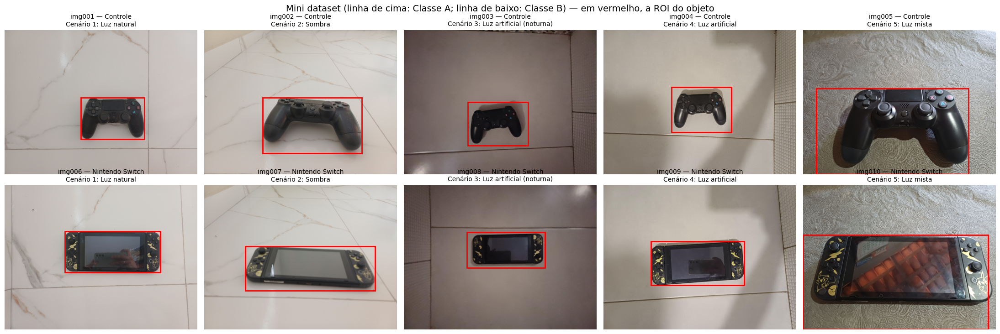

In [34]:
def roi_mask(iid, shape=(768, 1024)):
    m = np.zeros(shape, np.uint8)
    x, y, w, h = ROI[iid]
    m[y:y+h, x:x+w] = 255
    return m

fig, axes = plt.subplots(2, 5, figsize=(22, 7.5))
for ax, iid in zip(axes.ravel(), IDS):
    ax.imshow(cor[iid])
    x, y, w, h = ROI[iid]
    ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec='red', lw=2))
    ax.set_title(f"{iid} — {meta.loc[iid, 'Objeto']}\nCenário {meta.loc[iid, 'Cenário']}: {meta.loc[iid, 'Iluminação']}", fontsize=10)
    ax.axis('off')
fig.suptitle('Mini dataset (linha de cima: Classe A; linha de baixo: Classe B) — em vermelho, a ROI do objeto', fontsize=14)
plt.tight_layout()
plt.show()

### 1.3 Fatores de aquisição e hipótese inicial

**Fatores de aquisição que podem influenciar a análise:**

* **Fundo:** são três fundos bem diferentes (cerâmica clara com veios, piso cinza com pastilhas, tapete com relevo). Como o objeto ocupa de **9% a 63%** da imagem (coluna *Objeto ocupa*), na maior parte das fotos **o fundo é a maior parte dos pixels**. Qualquer medida calculada na imagem inteira tende a descrever o piso, e não o objeto.
* **Iluminação:** luz natural, sombra, luz artificial noturna (cena bem mais escura), sombra projetada forte (img004/img009) e luz mista. Isso desloca o brilho médio, cria reflexos especulares no plástico do controle e na tela do Switch (que reflete o celular e a mão de quem fotografou).
* **Distância e ângulo:** vistas de cima (cenários 1, 3 e 4), vista oblíqua baixa (cenário 2) e close inclinado (cenário 5). Isso muda a escala e a perspectiva dos detalhes.
* **Resolução e compressão:** as fotos têm 48 MP, mas foram convertidas de HEIC para JPEG, com taxas muito diferentes: de **0,22 a 1,48 bits/pixel**. As fotos sobre o tapete (img005, img010) são as que menos comprimem, porque o relevo do tapete tem muito detalhe fino, que o JPEG não consegue descartar.
* **Cor predominante:** os **dois objetos são pretos**. As únicas cores próprias são pequenas: botões coloridos do controle e estampas douradas do Switch.

**Diferenças visuais esperadas entre as classes:**

* **Controle:** formato curvo com empunhaduras, detalhes de **baixo contraste** (preto sobre preto: direcional, analógicos, grade do alto-falante) e quatro botões coloridos pequenos.
* **Switch:** formato retangular, uma tela grande, lisa e reflexiva no centro, e Joy-Cons com estampas douradas de **alto contraste** (raios, Pikachu, pokébolas).
* Em intensidade, as classes devem se parecer muito (dois objetos escuros sobre fundos claros). As diferenças estão na **estrutura** (forma, disposição dos botões, desenhos) e, em menor escala, na **cor** (dourado das estampas).

**Hipótese inicial:** os **descritores locais (ORB + matching)** devem ser os mais úteis, porque as estampas e os botões formam padrões estruturais específicos de cada objeto, que se repetem em todas as fotos da mesma classe. A segunda aposta é a **cor**, mas só se a análise for restrita ao objeto: o dourado é exclusivo do Switch, mas ocupa uma fração pequena da imagem. Espera-se que **histograma de intensidade e estatística global** falhem, porque vão refletir o fundo e a iluminação, e que a **textura** seja pouco discriminativa, porque nenhum dos dois objetos tem uma superfície texturizada.

---
## Parte 2 — Análise global: histogramas e estatística

### 2.1 Estatística global

Para cada imagem (em escala de cinza, resolução original 8000×6000) são calculados:

* **Média** $\mu = \frac{1}{N}\sum I(x,y)$ — brilho geral;
* **Variância** $\sigma^2 = \frac{1}{N}\sum (I-\mu)^2$ e **desvio padrão** $\sigma$ — contraste global (o quanto os níveis se espalham em torno da média);
* **Entropia de Shannon** $H = -\sum_{k=0}^{255} p_k \log_2 p_k$, em bits, onde $p_k$ é a fração de pixels com nível $k$. Vai de 0 (imagem de um só tom) a 8 bits (todos os 256 níveis igualmente frequentes) e mede o quanto o histograma é "espalhado" — **não** a quantidade de detalhe espacial: embaralhar os pixels de uma imagem não muda sua entropia.

Além da imagem inteira, as mesmas medidas são calculadas **só dentro da ROI do objeto** e só no fundo (fora da ROI), para verificar o quanto o fundo domina os números globais.

In [35]:
def entropia(img):
    p = np.bincount(img.ravel(), minlength=256) / img.size
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def estatisticas(img):
    v = img.astype(np.float64)
    return {'Média': v.mean(), 'Variância': v.var(), 'Desvio padrão': v.std(), 'Entropia (bits)': entropia(img)}

linhas = []
for iid in IDS:
    g = cv2.imread(meta.loc[iid, 'caminho'], cv2.IMREAD_GRAYSCALE)      # 8000x6000
    x, y, w, h = [int(round(v * ESCALA)) for v in ROI[iid]]
    obj = g[y:y+h, x:x+w]
    fundo_mask = np.ones(g.shape, bool); fundo_mask[y:y+h, x:x+w] = False
    s = estatisticas(g)
    so = estatisticas(obj)
    linhas.append({'Imagem': iid, 'Classe': meta.loc[iid, 'Classe'], 'Cenário': meta.loc[iid, 'Cenário'], **s,
                   'Média objeto': so['Média'], 'DP objeto': so['Desvio padrão'],
                   'Entropia objeto': so['Entropia (bits)'], 'Média fundo': g[fundo_mask].mean()})
    del g, obj, fundo_mask

stats = pd.DataFrame(linhas).set_index('Imagem')
stats

,Classe,Cenário,Média,Variância,Desvio padrão,Entropia (bits),Média objeto,DP objeto,Entropia objeto,Média fundo
Imagem,,,,,,,,,,
img001,A,1,172.76,1207.59,34.75,5.88,83.01,51.27,6.68,182.12
img002,A,2,176.81,1998.38,44.70,6.22,104.77,56.11,7.37,194.59
img003,A,3,99.24,610.13,24.70,6.38,69.03,45.93,6.08,102.36
img004,A,4,150.55,1067.57,32.67,6.52,119.57,65.41,6.42,153.90
img005,A,5,117.87,3158.86,56.20,7.59,78.28,49.18,7.22,152.83
img006,B,1,174.40,1954.34,44.21,6.19,74.85,35.74,6.66,190.68
img007,B,2,176.74,1654.69,40.68,6.23,110.87,46.16,7.12,193.85
img008,B,3,99.29,647.14,25.44,6.47,57.56,40.95,6.58,103.94
img009,B,4,149.38,1920.00,43.82,6.82,74.44,51.10,6.64,162.32


Para saber se uma medida **separa as classes**, não basta comparar médias: é preciso comparar a diferença entre as classes com a variação **dentro** de cada classe. A tabela abaixo usa a **razão de Fisher** $F = \frac{(\mu_A-\mu_B)^2}{\sigma_A^2+\sigma_B^2}$ (valores acima de ~1 indicam separação razoável) e verifica se as faixas [mín, máx] das duas classes se sobrepõem. A última coluna compara a diferença média **entre classes no mesmo cenário** com a diferença média **entre cenários na mesma classe**.

In [36]:
def separacao(df, colunas):
    res = []
    for c in colunas:
        a, b = df.loc[IDS_A, c].values, df.loc[IDS_B, c].values
        fisher = (a.mean() - b.mean())**2 / (a.var() + b.var())
        sobrepoe = not (a.max() < b.min() or b.max() < a.min())
        entre_classes = np.mean(np.abs(a - b))                          # pares de mesmo cenário
        entre_cenarios = np.mean([np.abs(v[i] - v[j]) for v in (a, b)
                                  for i in range(5) for j in range(i+1, 5)])
        res.append({'Medida': c, 'Classe A (média)': a.mean(), 'Classe B (média)': b.mean(),
                    'Faixa A': f'{a.min():.2f} – {a.max():.2f}', 'Faixa B': f'{b.min():.2f} – {b.max():.2f}',
                    'Faixas se sobrepõem?': 'sim' if sobrepoe else 'NÃO',
                    'Razão de Fisher': fisher,
                    'Δ entre classes (mesmo cenário)': entre_classes,
                    'Δ entre cenários (mesma classe)': entre_cenarios})
    return pd.DataFrame(res).set_index('Medida')

sep_stats = separacao(stats, ['Média', 'Desvio padrão', 'Entropia (bits)', 'Média objeto', 'DP objeto', 'Entropia objeto', 'Média fundo'])
sep_stats

,Classe A (média),Classe B (média),Faixa A,Faixa B,Faixas se sobrepõem?,Razão de Fisher,Δ entre classes (mesmo cenário),Δ entre cenários (mesma classe)
Medida,,,,,,,,
Média,143.44,142.96,99.24 – 176.81,99.29 – 176.74,sim,1.22e-04,1.16,42.43
Desvio padrão,38.61,42.31,24.70 – 56.20,25.44 – 57.42,sim,6.18e-02,5.32,14.25
Entropia (bits),6.52,6.69,5.88 – 7.59,6.19 – 7.76,sim,4.68e-02,0.18,0.74
Média objeto,90.93,81.30,69.03 – 119.57,57.56 – 110.87,sim,1.41e-01,16.27,24.85
DP objeto,53.58,44.42,45.93 – 65.41,35.74 – 51.10,sim,1.11e+00,9.16,8.38
Entropia objeto,6.75,6.89,6.08 – 7.37,6.58 – 7.44,sim,5.18e-02,0.25,0.56
Média fundo,157.16,162.04,102.36 – 194.59,103.94 – 193.85,sim,1.16e-02,5.18,42.48


**Interpretação — estatística global**

* **As medidas da imagem inteira descrevem o cenário, não o objeto.** Os pares de mesmo cenário têm médias quase idênticas: 172,8 × 174,4 (cenário 1), 176,8 × 176,7 (cenário 2), 99,2 × 99,3 (cenário 3), 150,6 × 149,4 (cenário 4) e 117,9 × 115,0 (cenário 5). A diferença média **entre as classes** num mesmo cenário é de **1,2 nível de cinza**, enquanto a diferença média **entre cenários** de uma mesma classe é de **42,4 níveis**. A razão de Fisher da média é praticamente zero (1,2 × 10⁻⁴), e as faixas das duas classes se sobrepõem por completo.
* **Desvio padrão e variância:** o Switch tem DP maior nos cenários 1 e 4 (44,2 × 34,8 e 43,8 × 32,7). Isso não indica uma propriedade da classe: o Switch ocupa uma área maior (14% contra 9,4%), e uma área escura maior sobre fundo claro aumenta o espalhamento dos níveis. Nos cenários 2, 3 e 5 a diferença praticamente some.
* **Entropia:** vai de 5,88 bits (img001) a 7,76 bits (img010), e segue o cenário. Os valores mais altos aparecem no cenário 5, porque o objeto grande e escuro, junto com o tapete em tons médios, espalha o histograma. Os mais baixos aparecem no cenário 1, onde o piso claro concentra a maior parte dos pixels em poucos níveis. Diferença média entre as classes: 0,18 bit. Entre cenários: 0,74 bit.
* **Só a ROI do objeto:** a separação melhora pouco. A única medida com Fisher > 1 é o **DP do objeto** (1,11), maior no controle (53,6 × 44,4). Mesmo assim, a ROI retangular do controle inclui mais piso claro nos cantos, por causa das empunhaduras curvas; já o Switch preenche quase todo o seu retângulo. Ou seja, a diferença vem mais da **forma** do objeto do que do seu material. A média da ROI (90,9 × 81,3) continua com faixas sobrepostas.
* **O que preserva e o que perde:** a estatística global resume a distribuição de brilho em 3 ou 4 números. Ela é barata e insensível à posição do objeto, mas perde **toda a informação espacial** e mistura objeto e fundo. Neste dataset, em que os dois objetos são pretos e o fundo muda a cada cenário, ela é praticamente uma **impressão digital da aquisição**.

### 2.2 Histogramas

#### 2.2.1 Histogramas de intensidade

Foram escolhidas **img001 e img002 (Classe A)** e **img006 e img007 (Classe B)**: são dois cenários, cada um fotografado com as duas classes. Em cada gráfico, as duas classes do **mesmo cenário** são sobrepostas — assim, qualquer diferença entre as curvas vem do objeto, e não da cena. Os histogramas são normalizados (fração de pixels), e a linha tracejada mostra o histograma só da ROI do objeto.

Para responder "onde a imagem concentra mais pixels", a tabela em seguida divide os níveis em **escuros (0–84)**, **médios (85–169)** e **claros (170–255)** para todas as 10 imagens.

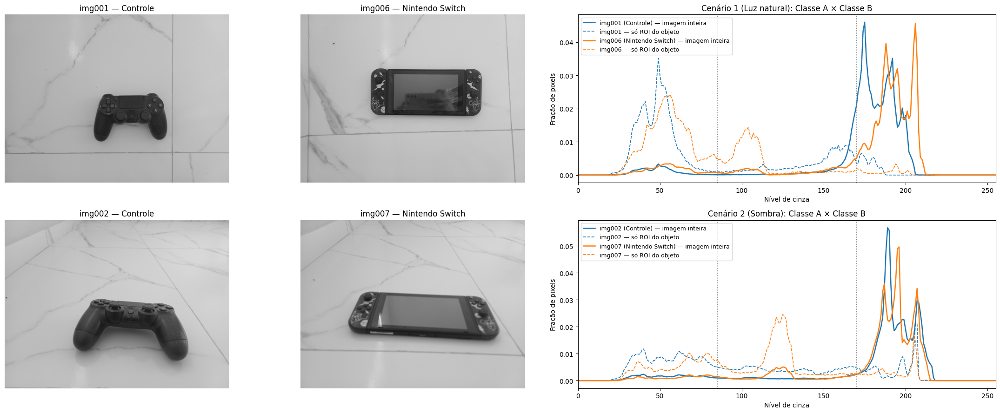

In [37]:
def hist_norm(img, mask=None, bins=256):
    h = cv2.calcHist([img], [0], mask, [bins], [0, 256]).ravel()
    return h / h.sum()

PARES_HIST = [('img001', 'img006'), ('img002', 'img007')]
fig, axes = plt.subplots(2, 3, figsize=(22, 9), gridspec_kw={'width_ratios': [1, 1, 1.6]})
for lin, (ia, ib) in enumerate(PARES_HIST):
    for col, iid in enumerate((ia, ib)):
        axes[lin, col].imshow(cinza[iid], cmap='gray', vmin=0, vmax=255)
        axes[lin, col].set_title(f"{iid} — {meta.loc[iid, 'Objeto']}")
        axes[lin, col].axis('off')
    ax = axes[lin, 2]
    for iid, c in ((ia, 'tab:blue'), (ib, 'tab:orange')):
        ax.plot(hist_norm(cinza[iid]), color=c, lw=1.8, label=f"{iid} ({meta.loc[iid, 'Objeto']}) — imagem inteira")
        ax.plot(hist_norm(cinza[iid], roi_mask(iid)), color=c, lw=1.2, ls='--', label=f'{iid} — só ROI do objeto')
    for lim in (85, 170):
        ax.axvline(lim, color='gray', ls=':', lw=1)
    ax.set_title(f"Cenário {meta.loc[ia, 'Cenário']} ({meta.loc[ia, 'Iluminação']}): Classe A × Classe B")
    ax.set_xlabel('Nível de cinza'); ax.set_ylabel('Fração de pixels'); ax.set_xlim(0, 255)
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

In [38]:
faixas = []
for iid in IDS:
    g = cinza[iid]
    faixas.append({'Imagem': iid, 'Classe': meta.loc[iid, 'Classe'], 'Cenário': meta.loc[iid, 'Cenário'],
                   'Escuros 0–84 (%)': 100 * np.mean(g < 85),
                   'Médios 85–169 (%)': 100 * np.mean((g >= 85) & (g < 170)),
                   'Claros 170–255 (%)': 100 * np.mean(g >= 170),
                   'Pico do histograma': int(np.argmax(hist_norm(g))),
                   'Escuros na ROI (%)': 100 * np.mean(g[roi_mask(iid) > 0] < 85)})
pd.DataFrame(faixas).set_index('Imagem')

,Classe,Cenário,Escuros 0–84 (%),Médios 85–169 (%),Claros 170–255 (%),Pico do histograma,Escuros na ROI (%)
Imagem,,,,,,,
img001,A,1,6.21,12.48,81.31,175,65.76
img002,A,2,9.34,8.00,82.65,189,47.19
img003,A,3,20.10,79.76,0.14,110,53.39
img004,A,4,4.61,57.36,38.03,176,41.38
img005,A,5,25.49,53.96,20.55,25,53.32
img006,B,1,9.50,9.89,80.61,206,67.56
img007,B,2,6.94,12.42,80.65,196,33.64
img008,B,3,20.40,79.46,0.15,120,73.53
img009,B,4,12.06,46.08,41.85,196,78.62


A figura a seguir sobrepõe os histogramas das **10 imagens**: à esquerda, imagem inteira; à direita, só a ROI do objeto. Cor = classe; estilo da linha = cenário. Se o histograma fosse um bom descritor de classe, as curvas azuis e laranjas formariam dois grupos.

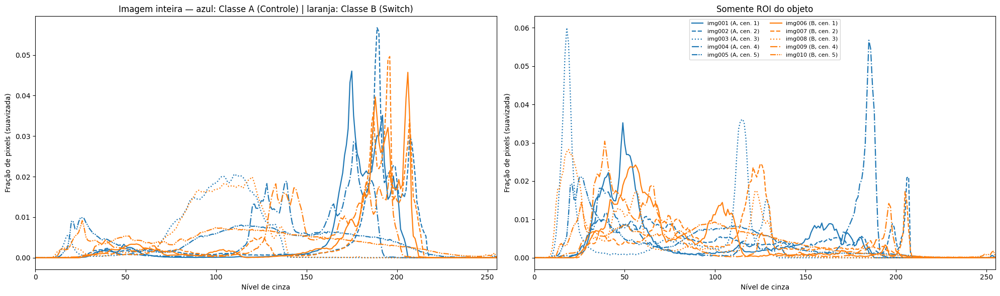

In [39]:
estilos = {1: '-', 2: '--', 3: ':', 4: '-.', 5: (0, (5, 1, 1, 1, 1, 1))}
fig, axes = plt.subplots(1, 2, figsize=(20, 6))
for iid in IDS:
    c = 'tab:blue' if meta.loc[iid, 'Classe'] == 'A' else 'tab:orange'
    ls = estilos[meta.loc[iid, 'Cenário']]
    rot = f"{iid} ({meta.loc[iid, 'Classe']}, cen. {meta.loc[iid, 'Cenário']})"
    axes[0].plot(cv2.GaussianBlur(hist_norm(cinza[iid]).reshape(1, -1), (1, 7), 0).ravel(), color=c, ls=ls, lw=1.6, label=rot)
    axes[1].plot(cv2.GaussianBlur(hist_norm(cinza[iid], roi_mask(iid)).reshape(1, -1), (1, 7), 0).ravel(), color=c, ls=ls, lw=1.6, label=rot)
axes[0].set_title('Imagem inteira — azul: Classe A (Controle) | laranja: Classe B (Switch)')
axes[1].set_title('Somente ROI do objeto')
for ax in axes:
    ax.set_xlabel('Nível de cinza'); ax.set_ylabel('Fração de pixels (suavizada)'); ax.set_xlim(0, 255)
axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

#### 2.2.2 Histogramas de cor

Para as mesmas quatro imagens são mostrados:
* o histograma **RGB** da imagem inteira (três canais sobrepostos);
* o histograma de **matiz (H, do HSV)** apenas dos pixels **coloridos** da ROI do objeto (saturação S > 60 e brilho V > 60). Em pixels quase cinzentos o matiz é instável e não significa nada, por isso eles são descartados. No OpenCV, H vai de 0 a 179 (≈ 0° a 358°): vermelho ≈ 0/179, amarelo ≈ 30, verde ≈ 60, azul ≈ 120.

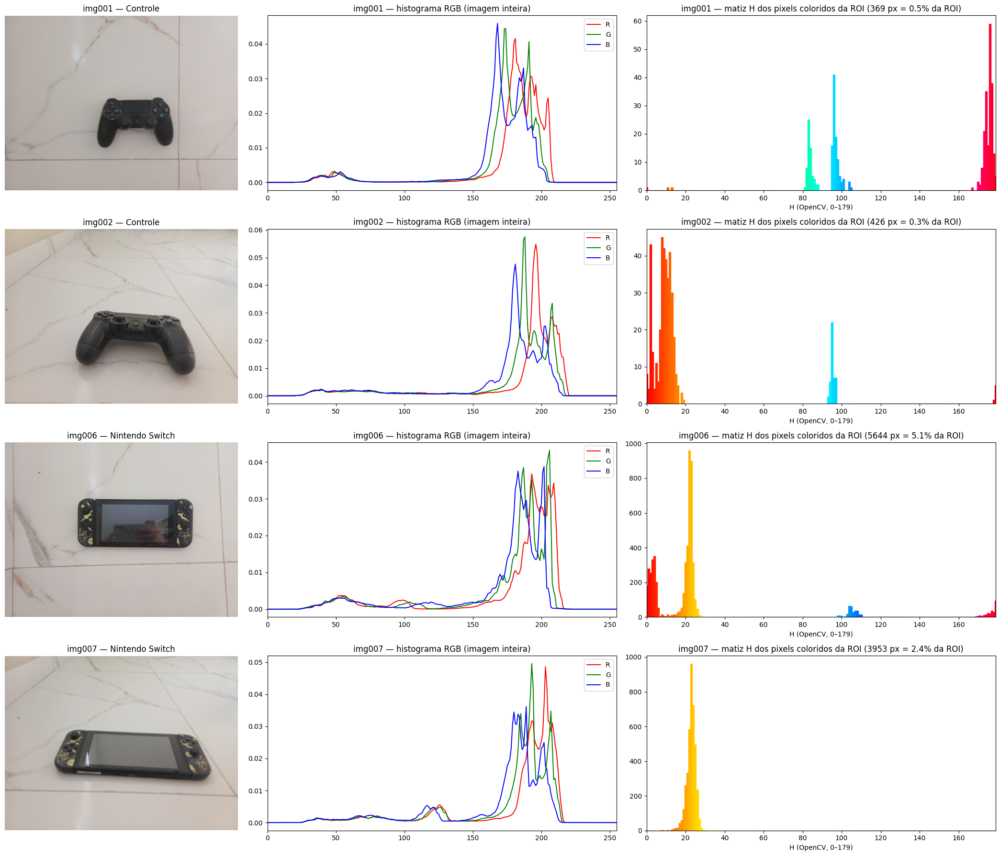

In [40]:
def mascara_colorida(iid, s_min=60, v_min=60):
    hsv = cv2.cvtColor(cor[iid], cv2.COLOR_RGB2HSV)
    m = ((hsv[..., 1] > s_min) & (hsv[..., 2] > v_min) & (roi_mask(iid) > 0)).astype(np.uint8) * 255
    return hsv, m

IMGS_COR = ['img001', 'img002', 'img006', 'img007']
fig, axes = plt.subplots(4, 3, figsize=(21, 18), gridspec_kw={'width_ratios': [0.8, 1.2, 1.2]})
for lin, iid in enumerate(IMGS_COR):
    axes[lin, 0].imshow(cor[iid]); axes[lin, 0].axis('off')
    axes[lin, 0].set_title(f"{iid} — {meta.loc[iid, 'Objeto']}")
    for canal, c in enumerate(['red', 'green', 'blue']):
        h = cv2.calcHist([cor[iid]], [canal], None, [256], [0, 256]).ravel()
        axes[lin, 1].plot(h / h.sum(), color=c, lw=1.4, label='RGB'[canal])
    axes[lin, 1].set_title(f'{iid} — histograma RGB (imagem inteira)'); axes[lin, 1].set_xlim(0, 255); axes[lin, 1].legend()
    hsv, m = mascara_colorida(iid)
    hh = cv2.calcHist([hsv], [0], m, [180], [0, 180]).ravel()
    barras = axes[lin, 2].bar(np.arange(180), hh, width=1.0)
    for k, b in enumerate(barras):
        b.set_color(plt.cm.hsv(k / 180))
    axes[lin, 2].set_xlim(0, 179)
    axes[lin, 2].set_title(f'{iid} — matiz H dos pixels coloridos da ROI ({int(m.sum() / 255)} px = {100 * m.sum() / 255 / (roi_mask(iid) > 0).sum():.1f}% da ROI)')
    axes[lin, 2].set_xlabel('H (OpenCV, 0–179)')
plt.tight_layout()
plt.show()

A tabela abaixo resume a cor das **10 imagens**: média de cada canal RGB (imagem inteira), canal dominante, saturação média, e duas medidas dentro da ROI do objeto — a fração de pixels **coloridos** e a fração de pixels **dourados/amarelos** (H entre 15 e 35, ou seja, ≈ 30°–70°, S > 60, V > 60), que correspondem às estampas do Pikachu nos Joy-Cons.

In [41]:
def fracao_dourada(iid):
    hsv, m = mascara_colorida(iid)
    dour = (m > 0) & (hsv[..., 0] >= 15) & (hsv[..., 0] <= 35)
    return 100 * dour.sum() / (roi_mask(iid) > 0).sum()

cores = []
for iid in IDS:
    rgb = cor[iid].reshape(-1, 3).astype(float)
    medias = rgb.mean(axis=0)
    hsv, m = mascara_colorida(iid)
    cores.append({'Imagem': iid, 'Classe': meta.loc[iid, 'Classe'], 'Cenário': meta.loc[iid, 'Cenário'],
                  'Média R': medias[0], 'Média G': medias[1], 'Média B': medias[2],
                  'Canal dominante': 'RGB'[int(np.argmax(medias))],
                  'R − B': medias[0] - medias[2],
                  'Saturação média (S)': hsv[..., 1].mean(),
                  'Pixels coloridos na ROI (%)': 100 * m.sum() / 255 / (roi_mask(iid) > 0).sum(),
                  'Pixels dourados na ROI (%)': fracao_dourada(iid)})
tab_cor = pd.DataFrame(cores).set_index('Imagem')
display(tab_cor)
separacao(tab_cor, ['Média R', 'R − B', 'Saturação média (S)', 'Pixels coloridos na ROI (%)', 'Pixels dourados na ROI (%)'])

,Classe,Cenário,Média R,Média G,Média B,Canal dominante,R − B,Saturação média (S),Pixels coloridos na ROI (%),Pixels dourados na ROI (%)
Imagem,,,,,,,,,,
img001,A,1,177.66,171.54,167.15,R,10.52,15.72,0.50,0.00
img002,A,2,181.89,175.71,169.50,R,12.40,18.20,0.27,0.01
img003,A,3,109.31,95.63,91.03,R,18.27,44.03,6.81,0.00
img004,A,4,158.06,148.96,137.86,R,20.21,33.96,1.97,1.64
img005,A,5,119.76,117.68,114.00,R,5.76,27.81,7.51,6.89
img006,B,1,178.72,173.27,169.54,R,9.19,16.68,5.11,3.02
img007,B,2,180.97,175.84,170.02,R,10.95,15.92,2.44,2.43
img008,B,3,108.75,95.79,91.89,R,16.86,41.99,4.36,3.03
img009,B,4,155.59,147.85,140.51,R,15.08,27.48,3.71,3.68


,Classe A (média),Classe B (média),Faixa A,Faixa B,Faixas se sobrepõem?,Razão de Fisher,Δ entre classes (mesmo cenário),Δ entre cenários (mesma classe)
Medida,,,,,,,,
Média R,149.34,148.71,109.31 – 181.89,108.75 – 180.97,sim,2.25e-04,1.06,40.67
R − B,13.43,12.57,5.76 – 20.21,9.19 – 16.86,sim,2.05e-02,2.87,5.63
Saturação média (S),27.94,28.22,15.72 – 44.03,15.92 – 41.99,sim,3.40e-04,4.60,14.69
Pixels coloridos na ROI (%),3.41,7.33,0.27 – 7.51,2.44 – 21.03,sim,2.67e-01,4.89,5.94
Pixels dourados na ROI (%),1.71,2.92,0.00 – 6.89,2.43 – 3.68,sim,2.01e-01,2.99,1.85


**Interpretação — histogramas**

* **Onde a imagem concentra mais pixels?** Depende do cenário, não da classe.
   * **Cenários 1 e 2:** mais de 80% dos pixels são **claros** (81,3% na img001, 82,7% na img002, 80,6% na img006, 80,7% na img007), com pico entre 175 e 206. É o piso de cerâmica.
   * **Cenário 3 (noturno):** cerca de 80% dos pixels são **médios** (79,8% e 79,5%), com pico entre 110 e 120.
   * **Cenário 4:** mistura de tons médios e claros (sombra projetada sobre piso claro).
   * **Cenário 5:** o pico está nos **escuros** (25–26), porque o objeto ocupa 47% a 63% da imagem.
   * Só dentro da ROI, todas as imagens têm moda nos **escuros (≈ 20–60)**: é o plástico preto, comum às duas classes. O Switch tem ainda um **segundo modo em ≈ 100–125** (curvas laranja tracejadas dos cenários 1 e 2), que corresponde à **tela** refletindo o ambiente. É a única diferença de intensidade que pode ser atribuída à classe, mas ela depende do que a tela está refletindo.
* **Existe canal de cor dominante?** Sim: o **vermelho (R)** é o maior nas 10 imagens (R − B de 5,8 a 20,2). Isso também é cena, não classe: o piso é bege, e a luz artificial dos cenários 3 e 4 é quente (R − B de 18,3 e 20,2 no controle; 16,9 e 15,1 no Switch). O R − B tem Fisher de 0,02 entre as classes.
* **As imagens da mesma classe são parecidas?** Não. No gráfico das 10 curvas, elas se agrupam pelo **estilo de linha (cenário)**, e não pela **cor (classe)**. img001 e img006 (classes diferentes, mesmo cenário) são muito mais parecidas que img001 e img003 (mesma classe, cenários diferentes).
* **O histograma ajudou a separar as classes?**
   * **Intensidade:** não.
   * **Cor (matiz da ROI): sim, é o sinal global mais útil.** No Switch, os pixels coloridos da ROI formam um **pico estreito em H ≈ 22 (≈ 44°, dourado)**: são as estampas. Nas img001 e img002 (controle), os poucos pixels coloridos (0,3% a 0,5% da ROI) se espalham entre vermelho/rosa (H ≈ 175, botões X e B), ciano (H ≈ 95, botão A) e verde (H ≈ 83, botão Y). A fração de pixels **dourados** na ROI é **estável no Switch, entre 2,4% e 3,7% nas 5 fotos**, e praticamente zero no controle nos cenários 1 a 3 (0,00% a 0,01%).
   * **Mas** a img004 (1,6%) e a img005 (6,9%) quebram essa separação. Uma checagem visual mostrou que esses pixels "dourados" **não estão no controle**: são a borda quente da sombra projetada (img004) e o tapete bege (img005), que entram na ROI retangular. Por isso o Fisher dessa medida fica em apenas 0,20. A cor **separa as classes se o objeto for bem segmentado**, e não separa com um simples retângulo.
* **O que preserva e o que perde:** o histograma preserva a **proporção de cada nível/cor** e é invariante à posição, rotação e escala do objeto. Em compensação, perde **onde** os pixels estão: 3% de dourado concentrado nas estampas e 3% de tapete bege espalhado no fundo produzem o mesmo histograma.

### 2.3 Relação com a tarefa anterior: original × versões derivadas

Para **img001 (Classe A)** e **img006 (Classe B)** foram regeneradas as versões da Atividade 1, com os mesmos parâmetros:

| Versão | Como foi gerada (Atividade 1) |
|---|---|
| Resolução 50% e 20% | `cv2.resize(img, (w//2, h//2))` e `(w//5, h//5)` — interpolação padrão (bilinear) |
| Quantização 32 níveis | `(img // 8) * 8` |
| Quantização 2 níveis | `(img > 127) * 255` |
| JPEG q = 30 | `cv2.imwrite(..., [cv2.IMWRITE_JPEG_QUALITY, 30])` |
| PNG | `cv2.imwrite(...png)` — sem perdas |

As medidas são feitas em escala de cinza. O JPEG e o PNG são codificados na versão **colorida** (como na Atividade 1) e convertidos para cinza depois da decodificação. O **PSNR** (dB) só é calculado para as versões de mesmo tamanho que a original (quanto maior, mais próxima; ∞ = idêntica).

In [42]:
def psnr(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64))**2)
    return np.inf if mse == 0 else 10 * np.log10(255**2 / mse)

def gerar_derivadas(caminho):
    bgr = cv2.imread(caminho)
    g = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    h, w = g.shape
    ok, jpg = cv2.imencode('.jpg', bgr, [cv2.IMWRITE_JPEG_QUALITY, 30])
    ok, png = cv2.imencode('.png', bgr)
    versoes = {
        'Original (JPEG da câmera)': (g, os.path.getsize(caminho)),
        'Resolução 50%': (cv2.resize(g, (w // 2, h // 2)), None),
        'Resolução 20%': (cv2.resize(g, (w // 5, h // 5)), None),
        'Quantização 32 níveis': ((g // 8) * 8, None),
        'Quantização 2 níveis': (((g > 127) * 255).astype(np.uint8), None),
        'JPEG q=30': (cv2.cvtColor(cv2.imdecode(jpg, cv2.IMREAD_COLOR), cv2.COLOR_BGR2GRAY), jpg.nbytes),
        'PNG (sem perdas)': (cv2.cvtColor(cv2.imdecode(png, cv2.IMREAD_COLOR), cv2.COLOR_BGR2GRAY), png.nbytes),
    }
    del bgr
    return versoes

derivadas, tab_deriv = {}, []
for iid in ['img001', 'img006']:
    versoes = gerar_derivadas(meta.loc[iid, 'caminho'])
    derivadas[iid] = versoes
    orig = versoes['Original (JPEG da câmera)'][0]
    for nome, (img, nbytes) in versoes.items():
        s = estatisticas(img)
        tab_deriv.append({'Imagem': iid, 'Versão': nome, 'Resolução': f'{img.shape[1]}×{img.shape[0]}',
                          'Níveis distintos': len(np.unique(img)), **s,
                          'Arquivo (KB)': nbytes / 1024 if nbytes else np.nan,
                          'PSNR (dB)': psnr(orig, img) if img.shape == orig.shape else np.nan})
tab_deriv = pd.DataFrame(tab_deriv).set_index(['Imagem', 'Versão'])
tab_deriv

Resolução  Níveis distintos   Média  Variância  Desvio padrão  Entropia (bits)  Arquivo (KB)  PSNR (dB)
Imagem Versão                                                                                                                            
img001 Original (JPEG da câmera)  8000×6000               219  172.76    1207.59          34.75             5.88       2497.95        inf
       Resolução 50%              4000×3000               210  172.81    1205.46          34.72             5.88           NaN        NaN
       Resolução 20%              1600×1200               207  172.76    1207.58          34.75             5.88           NaN        NaN
       Quantização 32 níveis      8000×6000                28  169.18    1211.89          34.81             2.97           NaN      35.48
       Quantização 2 níveis       8000×6000                 2  237.46    4165.84          64.54             0.36           NaN      10.81
       JPEG q=30                  8000×6000               223  172.84    1209.32          34.78             4.39        817.53      46.40
       PNG (sem perdas)           8000×6000               219  172.76    1207.59          34.75             5.88      12811.59        inf
img006 Original (JPEG da câmera)  8000×6000               233  174.40    1954.34          44.21             6.19       2368.82        inf
       Resolução 50%              4000×3000               225  174.45    1950.42          44.16             6.18           NaN        NaN
       Resolução 20%              1600×1200               222  174.40    1954.32          44.21             6.19           NaN        NaN
       Quantização 32 níveis      8000×6000                30  170.70    1947.12          44.13             3.27           NaN      35.41
       Quantização 2 níveis       8000×6000                 2  221.61    7398.72          86.02             0.56           NaN      11.65
       JPEG q=30                  8000×6000               245  174.49    1958.79          44.26             4.70        846.23      46.09
       PNG (sem perdas)           8000×6000               233  174.40    1954.34          44.21             6.19      12632.37        inf

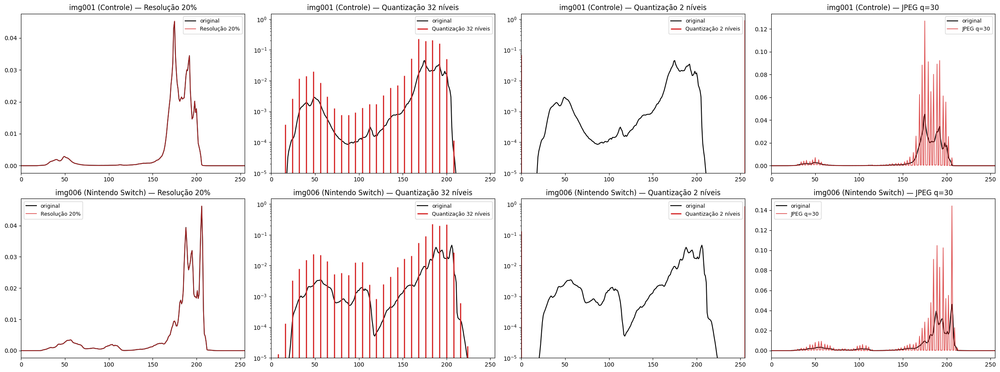

In [43]:
COMPARAR = ['Resolução 20%', 'Quantização 32 níveis', 'Quantização 2 níveis', 'JPEG q=30']
fig, axes = plt.subplots(2, 4, figsize=(24, 9))
for lin, iid in enumerate(derivadas):
    orig = derivadas[iid]['Original (JPEG da câmera)'][0]
    h0 = hist_norm(orig)
    for col, nome in enumerate(COMPARAR):
        ax = axes[lin, col]
        ax.plot(h0, color='black', lw=1.5, label='original')
        hv = hist_norm(derivadas[iid][nome][0])
        if 'Quantização' in nome:
            nz = np.nonzero(hv)[0]
            ax.vlines(nz, 0, hv[nz], color='tab:red', lw=2, label=nome)
            ax.set_yscale('log'); ax.set_ylim(1e-5, 1.5)
        else:
            ax.plot(hv, color='tab:red', lw=1.2, alpha=0.8, label=nome)
        ax.set_xlim(0, 255)
        ax.set_title(f"{iid} ({meta.loc[iid, 'Objeto']}) — {nome}")
        ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

Os histogramas mostram a distribuição de níveis, mas não mostram se o **detalhe útil** sobreviveu. Por isso, a figura abaixo amplia a mesma região de detalhe (botões X/A/B/Y do controle; Joy-Con esquerdo com a estampa do Switch) em cada versão, e exibe todas no mesmo tamanho de tela.

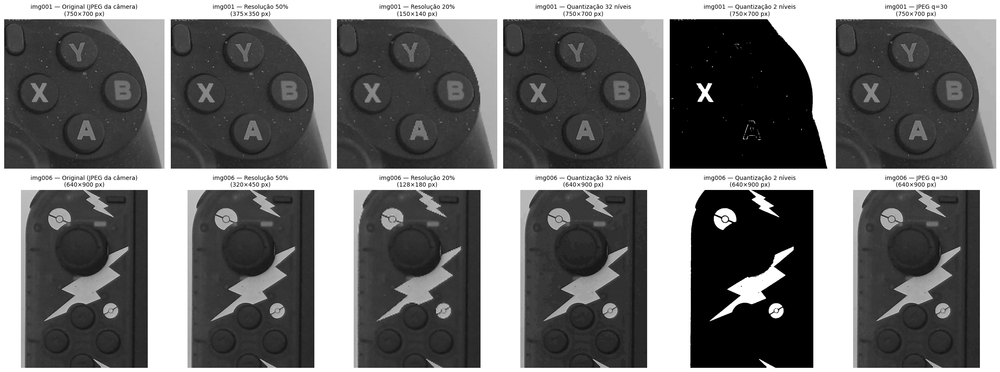

In [44]:
# região de detalhe em coordenadas da resolução original (x, y, largura, altura)
DETALHE = {'img001': (5000, 2900, 750, 700), 'img006': (2480, 2050, 640, 900)}
VERSOES_ZOOM = ['Original (JPEG da câmera)', 'Resolução 50%', 'Resolução 20%',
                'Quantização 32 níveis', 'Quantização 2 níveis', 'JPEG q=30']
fig, axes = plt.subplots(2, 6, figsize=(24, 9))
for lin, iid in enumerate(DETALHE):
    x, y, w, h = DETALHE[iid]
    for col, nome in enumerate(VERSOES_ZOOM):
        img = derivadas[iid][nome][0]
        f = img.shape[1] / 8000                    # escala da versão em relação à original
        rec = img[int(y*f):int((y+h)*f), int(x*f):int((x+w)*f)]
        axes[lin, col].imshow(rec, cmap='gray', vmin=0, vmax=255)
        axes[lin, col].set_title(f'{iid} — {nome}\n({rec.shape[1]}×{rec.shape[0]} px)', fontsize=10)
        axes[lin, col].axis('off')
plt.tight_layout()
plt.show()

**Interpretação — original × versões derivadas**

* **Redução de resolução (50% e 20%):** o histograma **praticamente não muda** (as curvas se sobrepõem), e as estatísticas também não. Na img001, a média foi de 172,76 para 172,76, o DP de 34,75 para 34,75 e a entropia de 5,88 para 5,88 bits; a img006 se comporta igual. No entanto, o recorte ampliado mostra perda real: em 20%, a região dos botões cai de 750×700 para 150×140 px, as bordas das letras ficam serrilhadas e os raios do Switch ficam em degraus. **As medidas globais são cegas à resolução**: reduzir a imagem preserva a proporção de cada nível de cinza, e é só isso que elas medem. A perda de informação útil é real, mas o histograma não a detecta.
* **Quantização em 32 níveis:** o histograma vira um **"pente"** de 28–30 linhas, e a **entropia cai pela metade** (5,88 → 2,97 bits; 6,19 → 3,27 bits), porque agora só há ~30 valores possíveis. Mesmo assim, o recorte é visualmente idêntico ao original e o PSNR é de 35,5 dB. A média cai cerca de 3,6 níveis, porque `(img // 8) * 8` sempre arredonda para baixo. **A entropia caiu muito sem perda perceptível de informação útil**: a entropia mede o espalhamento do histograma, não o detalhe da cena.
* **Quantização em 2 níveis:** a entropia vai a 0,36 e 0,56 bit, e o PSNR cai para 10,8 e 11,7 dB. Aqui a diferença entre as classes aparece: no **controle**, as letras dos botões quase somem (sobram o "X" e parte do "A") e o corpo vira um bloco preto; no **Switch**, as estampas douradas **sobrevivem inteiras** como formas brancas. É a mesma conclusão da Atividade 3: os detalhes do controle têm baixo contraste (Δ ≈ 50 níveis) e são os primeiros a desaparecer; as estampas do Switch (Δ ≈ 120) resistem.
* **JPEG q = 30:** o arquivo cai de 2.498 KB para 818 KB (img001) e de 2.369 KB para 846 KB (img006), com PSNR alto (46,4 e 46,1 dB) e nenhuma diferença visível no recorte. Ainda assim, **a entropia caiu** (5,88 → 4,39; 6,19 → 4,70), e o histograma ficou cheio de **picos isolados** na região do piso. Isso acontece porque o JPEG quantiza os coeficientes da DCT em blocos de 8×8: os gradientes suaves do piso viram blocos de tons repetidos, e alguns níveis passam a concentrar muitos pixels. O número de níveis distintos até **aumentou** (219 → 223; 233 → 245), por causa dos artefatos de *ringing* nas bordas. É mais um caso em que a entropia muda sem perda útil perceptível.
* **PNG:** as estatísticas são **idênticas** à original (PSNR = ∞), porque o PNG não tem perdas. O arquivo, porém, tem 12,8 MB contra os 2,4 MB do JPEG original da câmera. Além disso, o PNG não recupera nada do que já tinha sido descartado quando a câmera salvou a foto.
* **A entropia caiu ou aumentou?** Caiu em todas as versões com perda de níveis (quantização e JPEG), não mudou na redução de resolução nem no PNG, e **não aumentou em nenhum caso**.
* **Houve perda perceptível de informação útil?** Só na **quantização em 2 níveis** (grave para o controle) e, em menor grau, na **resolução de 20%**. Curiosamente, nenhuma das duas é a versão em que o histograma mais mudou.

---
## Parte 3 — Análise local: pontos de interesse, descritores e matching

As análises locais são feitas em escala de cinza na resolução de trabalho (1024×768). Nessa resolução, um canto ou um botão ocupa alguns pixels, que é a escala para a qual os detectores (janela de Shi-Tomasi, patch de 31×31 do ORB) foram pensados; em 48 MP, eles responderiam sobretudo a grão do sensor e a artefatos de JPEG.

### 3.1 Pontos de interesse

#### 3.1.1 Cantos — Shi-Tomasi

O detector de Shi-Tomasi calcula, em cada pixel, a matriz de estrutura $M$ (soma dos produtos dos gradientes $I_x, I_y$ numa janela) e usa como resposta o **menor autovalor**, $R = \min(\lambda_1, \lambda_2)$. Só é canto o ponto onde a intensidade varia muito em **duas direções**: uma borda reta tem um autovalor alto e outro baixo, e é rejeitada.

Parâmetros (`cv2.goodFeaturesToTrack`): até 300 cantos, `qualityLevel = 0.01` (aceita respostas ≥ 1% da maior) e `minDistance = 7` px. Ele é aplicado em uma imagem de cada classe nos cenários 1 e 5, e a tabela conta quantos cantos caíram **no objeto** e quantos **no fundo**.

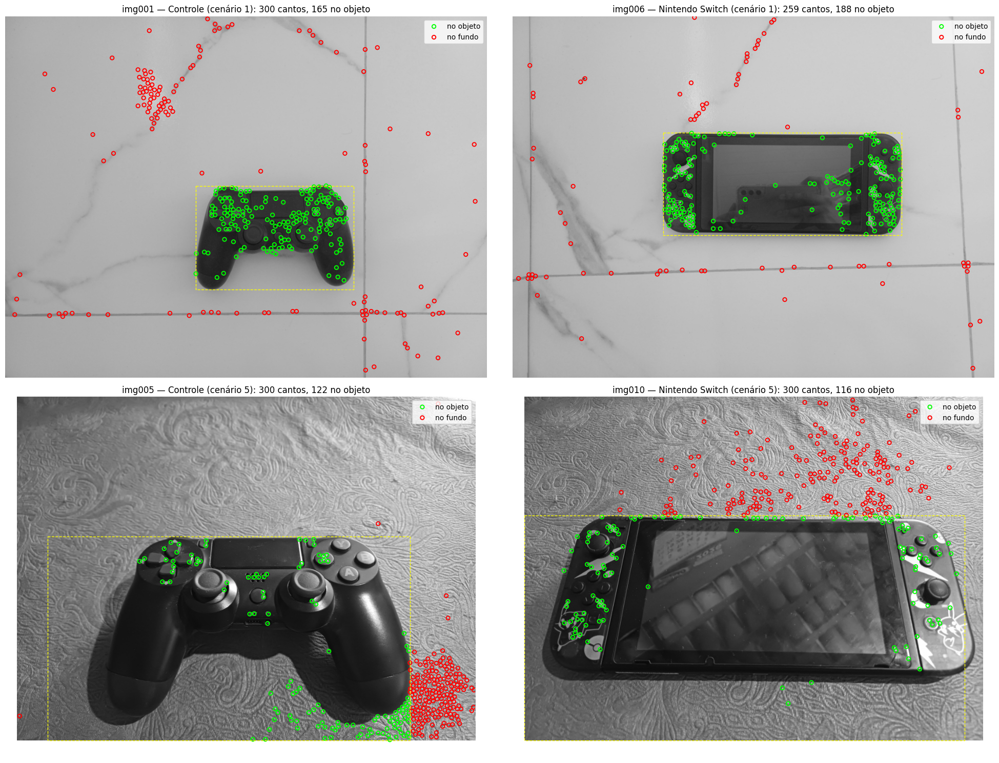

,Objeto,Cenário,Cantos detectados,No objeto,No fundo,% no objeto,Objeto ocupa (% da imagem)
Imagem,,,,,,,
img001,Controle,1,300,165,135,55.00,9.44
img006,Nintendo Switch,1,259,188,71,72.59,14.05
img005,Controle,5,300,122,178,40.67,46.91
img010,Nintendo Switch,5,300,116,184,38.67,62.87


In [45]:
def shi_tomasi(img, n=300):
    c = cv2.goodFeaturesToTrack(img, maxCorners=n, qualityLevel=0.01, minDistance=7)
    return np.zeros((0, 2)) if c is None else c.reshape(-1, 2)

IMGS_CANTOS = ['img001', 'img006', 'img005', 'img010']
fig, axes = plt.subplots(2, 2, figsize=(20, 15))
tab_cantos = []
for ax, iid in zip(axes.ravel(), IMGS_CANTOS):
    pts = shi_tomasi(cinza[iid])
    dentro = roi_mask(iid)[pts[:, 1].astype(int), pts[:, 0].astype(int)] > 0
    ax.imshow(cinza[iid], cmap='gray', vmin=0, vmax=255)
    ax.scatter(pts[dentro, 0], pts[dentro, 1], s=28, facecolors='none', edgecolors='lime', lw=1.4, label='no objeto')
    ax.scatter(pts[~dentro, 0], pts[~dentro, 1], s=28, facecolors='none', edgecolors='red', lw=1.4, label='no fundo')
    x, y, w, h = ROI[iid]
    ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec='yellow', lw=1, ls='--'))
    ax.set_title(f"{iid} — {meta.loc[iid, 'Objeto']} (cenário {meta.loc[iid, 'Cenário']}): {len(pts)} cantos, {dentro.sum()} no objeto")
    ax.legend(loc='upper right'); ax.axis('off')
    tab_cantos.append({'Imagem': iid, 'Objeto': meta.loc[iid, 'Objeto'], 'Cenário': meta.loc[iid, 'Cenário'],
                       'Cantos detectados': len(pts), 'No objeto': int(dentro.sum()), 'No fundo': int((~dentro).sum()),
                       '% no objeto': 100 * dentro.mean(), 'Objeto ocupa (% da imagem)': meta.loc[iid, 'Objeto ocupa (%)']})
plt.tight_layout()
plt.show()
pd.DataFrame(tab_cantos).set_index('Imagem')

**Interpretação — Shi-Tomasi**

* **Os cantos se concentram no objeto, desde que o fundo seja liso.** Na img001, 165 dos 300 cantos (55%) estão no controle, que ocupa só 9,4% da imagem: a densidade de cantos no objeto é **≈ 12 vezes maior** que no fundo. Na img006 (Switch), 188 de 259 (73%) estão no objeto, com densidade ≈ 16 vezes maior. No controle, os cantos estão no direcional, nos botões, no touchpad e nos analógicos. No Switch, eles se concentram nos **Joy-Cons** (contornos das estampas e botões), e **quase nenhum aparece na tela**, que é lisa.
* **No fundo, os cantos marcam o encontro de estruturas:** cruzamentos dos rejuntes, bifurcações dos veios de mármore e uma mancha na cerâmica (aglomerado no canto superior esquerdo da img001). Bordas retas, como um rejunte sozinho, são rejeitadas, como prevê o critério do menor autovalor.
* **Com fundo texturizado, o detector se perde:** no cenário 5, o **relevo do tapete** gera cantos fortes, e a maioria dos pontos (178 de 300 na img005; 184 de 300 na img010) cai fora do objeto. Parte dos pontos verdes da img005 também é tapete, que entra na ROI retangular abaixo do controle.
* A img006 parou em 259 cantos, abaixo do limite de 300: as estampas douradas geram uma resposta máxima muito alta, e o limiar relativo (1% do máximo) fica mais exigente.
* **O que preserva e o que perde:** o Shi-Tomasi preserva a **posição** das estruturas 2D (cantos), que é o "esqueleto" do objeto. Mas ele não descreve a aparência ao redor de cada ponto, então sozinho **não permite comparar** duas imagens. Também não distingue objeto de fundo: responde a qualquer canto.

#### 3.1.2 Blobs — Laplaciano do Gaussiano (`blob_log`)

O `blob_log` filtra a imagem com o Laplaciano do Gaussiano normalizado em várias escalas σ e procura máximos locais no espaço (x, y, σ). Ele responde a **regiões claras e aproximadamente circulares sobre fundo escuro**, com raio ≈ σ√2. No nosso dataset, os candidatos naturais são os **botões** do controle e as **estampas e botões** dos Joy-Cons — detalhes claros sobre plástico preto.

O método é aplicado à ROI das imagens do cenário 5 (objetos mais próximos, img005 e img010) e, para comparação, à ROI da img006 (o mesmo Switch, mas fotografado de longe, no cenário 1). Parâmetros: `min_sigma = 2`, `max_sigma = 12`, `num_sigma = 11`, `threshold = 0.2`, `exclude_border = 8`, sobre a imagem em cinza normalizada para [0, 1]. Num primeiro teste com `threshold = 0.08` foram detectados cerca de 500 blobs na ROI da img005 e 850 na da img010, quase todos no relevo do tapete; o limiar de 0.2 mantém só as respostas mais fortes.

Para medir se o detector encontrou os detalhes do objeto, cada blob é classificado como **"sobre plástico escuro"** quando a mediana de um anel ao redor dele (de *r* a 2*r*) é menor que 80. É o caso de um botão claro ou de uma estampa dourada sobre o corpo preto; um blob do tapete ou da borda do objeto com o piso não passa nesse teste.

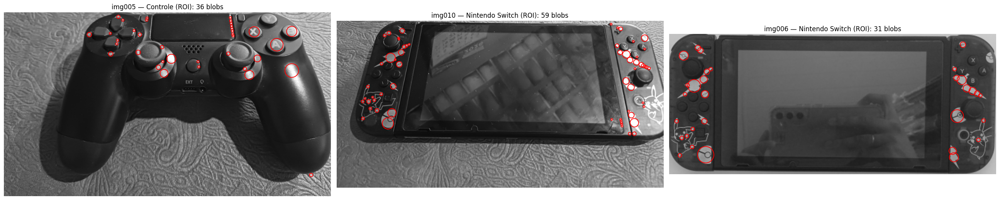

,Região,Blobs,Raio médio (px),Sobre plástico escuro,"Em outras regiões (fundo, bordas)",% sobre plástico escuro
Imagem,,,,,,
img005,ROI,36,5.50,21,15,58.33
img010,ROI,59,5.58,27,32,45.76
img006,ROI,31,4.79,31,0,100.00


In [46]:
def blobs(img):
    b = blob_log(img.astype(float) / 255, min_sigma=2, max_sigma=12, num_sigma=11, threshold=0.2,
                 exclude_border=8)          # descarta blobs colados à borda do recorte (faixas de piso)
    b[:, 2] *= np.sqrt(2)                       # sigma -> raio
    return b

def vizinhanca_escura(img, yb, xb, r, limiar=80):
    # um blob "útil" é um ponto claro cercado de plástico escuro: mediana de um anel (r a 2r) abaixo do limiar
    yy, xx = np.ogrid[:img.shape[0], :img.shape[1]]
    d2 = (yy - yb)**2 + (xx - xb)**2
    anel = (d2 > r**2) & (d2 <= (2 * r)**2)
    return np.median(img[anel]) < limiar

def recorte_roi(img, iid):
    x, y, w, h = ROI[iid]
    return img[y:y+h, x:x+w]

casos_blob = [('img005', recorte_roi(cinza['img005'], 'img005'), 'ROI'),
              ('img010', recorte_roi(cinza['img010'], 'img010'), 'ROI'),
              ('img006', recorte_roi(cinza['img006'], 'img006'), 'ROI')]
fig, axes = plt.subplots(1, 3, figsize=(26, 7))
tab_blobs = []
for ax, (iid, img, onde) in zip(axes, casos_blob):
    b = blobs(img)
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    for yb, xb, r in b:
        ax.add_patch(plt.Circle((xb, yb), r, color='red', fill=False, lw=1.3))
    ax.set_title(f"{iid} — {meta.loc[iid, 'Objeto']} ({onde}): {len(b)} blobs")
    ax.axis('off')
    sobre_escuro = np.array([vizinhanca_escura(img, *bl) for bl in b], bool)
    tab_blobs.append({'Imagem': iid, 'Região': onde, 'Blobs': len(b),
                      'Raio médio (px)': b[:, 2].mean() if len(b) else np.nan,
                      'Sobre plástico escuro': int(sobre_escuro.sum()),
                      'Em outras regiões (fundo, bordas)': int((~sobre_escuro).sum()),
                      '% sobre plástico escuro': 100 * sobre_escuro.mean() if len(b) else np.nan})
plt.tight_layout()
plt.show()
pd.DataFrame(tab_blobs).set_index('Imagem')

**Interpretação — blobs (LoG)**

* **Com o objeto próximo, o LoG encontra os detalhes claros sobre o plástico preto.**
   * **img005 (controle):** os blobs estão nas setas do direcional, nos botões X/A/Y/B, nos reflexos de borracha dos analógicos e numa fileira de pontos na borda do touchpad (reflexo da barra de luz).
   * **img010 (Switch):** os blobs estão nos raios, pokébolas, olhos do Pikachu e botões dos Joy-Cons, além de pequenos reflexos na tela.
   * **img006 (Switch de longe):** os 31 blobs estão **todos** sobre os Joy-Cons (100% sobre plástico escuro). Nenhum aparece na tela nem no piso.
* **A medida "sobre plástico escuro" é aproximada:** na img010, os Joy-Cons estão mais iluminados e as estampas são densas, então a mediana do anel muitas vezes passa de 80. Por isso só 46% dos blobs são contados como "sobre plástico escuro", embora visualmente quase todos estejam no console. Na img005, os 15 restantes são principalmente os anéis de borracha dos analógicos (cinza médio) e um ponto do tapete.
* **Limitações:**
   * **Depende de parâmetros e escala.** Com `threshold = 0.08`, o detector encontrou cerca de 500 e 850 blobs, quase todos no relevo do tapete. Na img001 inteira (controle pequeno, cenário 1), com `threshold = 0.2`, não encontrou **nenhum** blob: ali os botões têm raio de ~5 px e contraste fraco, e ficam abaixo do limiar.
   * **Não é discriminativo:** as duas classes têm "pontos claros redondos" (botões num caso, estampas no outro). Contar ou medir blobs não diz qual é o objeto: a contagem muda mais com a distância e o limiar do que com a classe.
   * **É lento:** o filtro é aplicado em 11 escalas.
* **O que preserva e o que perde:** o LoG preserva **posição e tamanho** de regiões arredondadas, e é útil para **localizar** botões e estampas. Mas ele perde a forma (um raio e uma pokébola viram apenas círculos de raios diferentes) e não tem descritor para comparar imagens.

### 3.2 Descritores locais — ORB

O **ORB** (*Oriented FAST and Rotated BRIEF*) detecta cantos com o FAST em uma pirâmide de 8 escalas, atribui a cada ponto uma orientação (centroide de intensidade) e descreve o patch de 31×31 ao redor com **256 comparações binárias** de intensidade (BRIEF rotacionado). O descritor é um vetor de 32 bytes; a semelhança entre dois descritores é a **distância de Hamming** (número de bits diferentes, de 0 a 256).

**Pares escolhidos:**

| Par | Tipo | Por quê |
|---|---|---|
| img001 × img004 | mesma classe (Controle) | mesma vista de cima, cenários diferentes (luz natural × luz artificial com sombra) |
| img006 × img009 | mesma classe (Switch) | idem, para o Switch |
| img001 × img006 | classes diferentes | **mesmo cenário** (mesmo piso, mesma luz): o caso mais difícil, porque o fundo é igual |

Cada par é analisado de duas formas: com o ORB na **imagem inteira** e com o ORB **restrito à ROI do objeto** (máscara). Usa-se `nfeatures = 1500`.

In [47]:
orb = cv2.ORB_create(nfeatures=1500)

def orb_extrair(iid, usar_roi):
    return orb.detectAndCompute(cinza[iid], roi_mask(iid) if usar_roi else None)

feats = {(iid, r): orb_extrair(iid, r) for iid in IDS for r in (False, True)}

PARES = [('img001', 'img004', 'mesma classe (Controle)'),
         ('img006', 'img009', 'mesma classe (Switch)'),
         ('img001', 'img006', 'classes diferentes (mesmo cenário)')]

tab_kp = []
for iid in sorted({i for p in PARES for i in p[:2]}):
    kp, _ = feats[(iid, False)]
    kp_roi, _ = feats[(iid, True)]
    pts = np.array([k.pt for k in kp]).astype(int)
    dentro = roi_mask(iid)[pts[:, 1], pts[:, 0]] > 0
    tab_kp.append({'Imagem': iid, 'Objeto': meta.loc[iid, 'Objeto'],
                   'Keypoints (imagem inteira)': len(kp), 'Desses, no objeto': int(dentro.sum()),
                   '% no objeto': 100 * dentro.mean(), 'Objeto ocupa (% da imagem)': meta.loc[iid, 'Objeto ocupa (%)'],
                   'Keypoints (só ROI)': len(kp_roi)})
pd.DataFrame(tab_kp).set_index('Imagem')

,Objeto,Keypoints (imagem inteira),"Desses, no objeto",% no objeto,Objeto ocupa (% da imagem),Keypoints (só ROI)
Imagem,,,,,,
img001,Controle,390,330,84.62,9.44,311
img004,Controle,1242,455,36.63,9.77,572
img006,Nintendo Switch,1330,1273,95.71,14.05,1280
img009,Nintendo Switch,1464,1406,96.04,14.73,1453


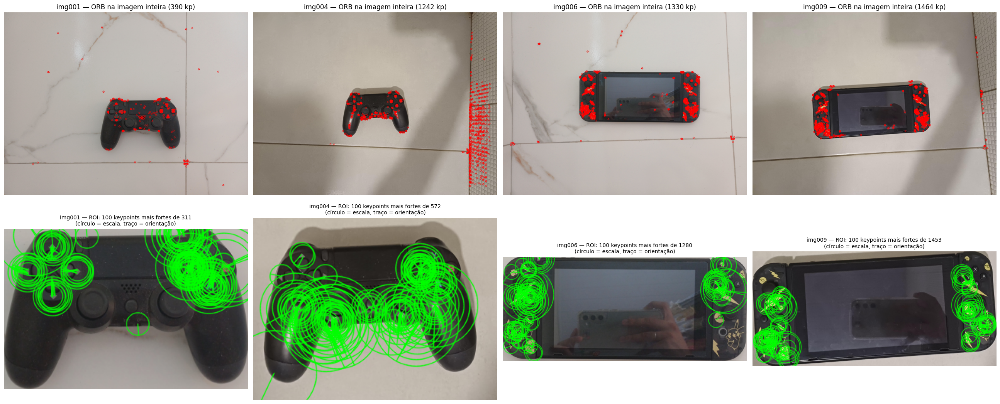

In [48]:
fig, axes = plt.subplots(2, 4, figsize=(26, 11))
for col, iid in enumerate(['img001', 'img004', 'img006', 'img009']):
    kp, _ = feats[(iid, False)]
    viz = cv2.drawKeypoints(cor[iid], kp, None, color=(255, 0, 0))
    axes[0, col].imshow(viz); axes[0, col].axis('off')
    axes[0, col].set_title(f'{iid} — ORB na imagem inteira ({len(kp)} kp)')
    kp_r, _ = feats[(iid, True)]
    fortes = sorted(kp_r, key=lambda k: -k.response)[:100]       # só os 100 de maior resposta, para legibilidade
    x, y, w, h = ROI[iid]
    viz = cv2.drawKeypoints(cor[iid], fortes, None, color=(0, 255, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    axes[1, col].imshow(viz[y:y+h, x:x+w]); axes[1, col].axis('off')
    axes[1, col].set_title(f'{iid} — ROI: 100 keypoints mais fortes de {len(kp_r)}\n(círculo = escala, traço = orientação)', fontsize=10)
plt.tight_layout()
plt.show()

**Interpretação — keypoints ORB e regiões informativas**

* **O fundo pode "roubar" os keypoints.** Na img001, 85% dos 390 keypoints estão no controle. Na img004, porém, só **37% dos 1.242** estão no objeto: a maioria cai nas **pastilhas** do lado direito, uma grade regular cheia de cantos. No Switch (img006, img009), 96% estão no objeto: as estampas geram respostas mais fortes que qualquer coisa no piso.
* **O Switch tem muito mais pontos detectáveis que o controle.** Restrito à ROI, o controle tem 311 e 572 keypoints, e o Switch tem 1.280 e 1.453 (o teto é 1.500). O FAST exige que um arco de vizinhos seja bem mais claro ou bem mais escuro que o centro. As estampas douradas sobre plástico preto atendem esse critério ao longo de todo o contorno; os detalhes preto-sobre-preto do controle, só em poucos lugares.
* **Regiões mais informativas:** no **controle**, o direcional, os botões ABXY e as bordas dos analógicos. Na img004, os pontos mais fortes estão nas **bordas das sombras** sob os analógicos e as empunhaduras, que são criadas pela luz e mudam de foto para foto. No **Switch**, os pontos se concentram nos dois Joy-Cons. A **tela, que ocupa a maior parte do console, quase não tem keypoints**: é lisa, e o que aparece nela é reflexo.
* **O que preserva e o que perde:** o ORB preserva a **aparência local** (256 comparações de intensidade num patch de 31×31) em posições específicas, com orientação e escala. Ele perde o **contexto global** (sozinho, um keypoint não sabe se está no objeto ou no fundo) e a **cor**, porque trabalha em cinza.

### 3.3 Matching

O casamento usa o `cv2.BFMatcher` com **`NORM_HAMMING`**, a distância correta para descritores binários como o ORB (a distância euclidiana `NORM_L2` é para descritores reais como SIFT). São reportados três níveis de filtragem, do mais permissivo ao mais exigente:

1. **Matches brutos** — `crossCheck=True`: o par (a, b) é aceito se b é o vizinho mais próximo de a **e** a é o mais próximo de b. Sempre gera muitos pares, porque todo descritor tem *algum* vizinho mais próximo.
2. **Teste da razão de Lowe** — `knnMatch(k=2)`, mantém o match só se $d_1 < 0{,}75\,d_2$, isto é, se o melhor vizinho é claramente melhor que o segundo. Elimina correspondências ambíguas (padrões repetidos, regiões lisas).
3. **Inliers geométricos (RANSAC)** — estima uma homografia com os matches que passaram no teste da razão e conta quantos são consistentes com ela (erro < 5 px). É a medida de **qualidade**: matches corretos de um mesmo objeto rígido precisam concordar entre si sobre a transformação. A homografia é uma aproximação (o objeto é 3D), mas é adequada para as vistas de cima.

Nas figuras, **verde = inlier** e **vermelho = match que passou na razão, mas foi rejeitado pelo RANSAC**.

In [49]:
bf_cross = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
bf_knn = cv2.BFMatcher(cv2.NORM_HAMMING)

def casar(f1, f2, razao=0.75):
    kp1, d1 = f1; kp2, d2 = f2
    res = {'kp1': len(kp1), 'kp2': len(kp2), 'brutos': 0, 'razao': 0, 'inliers': 0,
           'hamming_brutos': np.nan, 'hamming_razao': np.nan, 'bons': [], 'mask': [], 'H': None}
    if d1 is None or d2 is None or len(kp1) < 2 or len(kp2) < 2:
        return res
    brutos = bf_cross.match(d1, d2)
    res['brutos'] = len(brutos)
    res['hamming_brutos'] = np.mean([m.distance for m in brutos]) if brutos else np.nan
    bons = [m for m, n in (p for p in bf_knn.knnMatch(d1, d2, k=2) if len(p) == 2) if m.distance < razao * n.distance]
    bons = sorted(bons, key=lambda m: m.distance)
    res['razao'], res['bons'] = len(bons), bons
    res['hamming_razao'] = np.mean([m.distance for m in bons]) if bons else np.nan
    if len(bons) >= 4:
        p1 = np.float32([kp1[m.queryIdx].pt for m in bons])
        p2 = np.float32([kp2[m.trainIdx].pt for m in bons])
        H, mask = cv2.findHomography(p1, p2, cv2.RANSAC, 5.0)
        if mask is not None:
            res['mask'] = mask.ravel().astype(bool)
            res['inliers'] = int(mask.sum())
            res['H'] = H
    return res

def desenhar(iid1, iid2, f1, f2, r, ax, titulo, max_linhas=60):
    bons = r['bons'][:max_linhas]
    mask = list(r['mask'][:max_linhas]) if len(r['mask']) else [False] * len(bons)
    inl = [m for m, k in zip(bons, mask) if k]
    out = [m for m, k in zip(bons, mask) if not k]
    viz = cv2.drawMatches(cor[iid1], f1[0], cor[iid2], f2[0], out, None, matchColor=(255, 0, 0),
                          singlePointColor=None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    viz = cv2.drawMatches(cor[iid1], f1[0], cor[iid2], f2[0], inl, viz, matchColor=(0, 255, 0),
                          flags=cv2.DrawMatchesFlags_DRAW_OVER_OUTIMG | cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    ax.imshow(viz); ax.axis('off')
    ax.set_title(titulo, fontsize=11)

tab_match = []
resultados = {}
for usar_roi in (False, True):
    for i1, i2, tipo in PARES:
        r = casar(feats[(i1, usar_roi)], feats[(i2, usar_roi)])
        resultados[(i1, i2, usar_roi)] = r
        tab_match.append({'Par': f'{i1} × {i2}', 'Tipo': tipo, 'Região': 'só ROI' if usar_roi else 'imagem inteira',
                          'Keypoints (1 | 2)': f"{r['kp1']} | {r['kp2']}", 'Matches brutos': r['brutos'],
                          'Hamming médio (brutos)': r['hamming_brutos'], 'Após razão de Lowe': r['razao'],
                          'Hamming médio (razão)': r['hamming_razao'], 'Inliers RANSAC': r['inliers'],
                          'Inliers / brutos (%)': 100 * r['inliers'] / max(r['brutos'], 1)})
tab_match = pd.DataFrame(tab_match).set_index(['Região', 'Par'])
tab_match

Tipo Keypoints (1 | 2)  Matches brutos  Hamming médio (brutos)  Após razão de Lowe  Hamming médio (razão)  Inliers RANSAC  Inliers / brutos (%)
Região         Par                                                                                                                                                                                           
imagem inteira img001 × img004             mesma classe (Controle)        390 | 1242             133                   57.43                  21                  42.86              15                 11.28
               img006 × img009               mesma classe (Switch)       1330 | 1464             592                   42.25                 250                  34.11             240                 40.54
               img001 × img006  classes diferentes (mesmo cenário)        390 | 1330             151                   55.95                  10                  31.00               2                  1.32
só ROI         img001 × img004             mesma classe (Controle)         311 | 572             116                   56.14                  17                  42.24              14                 12.07
               img006 × img009               mesma classe (Switch)       1280 | 1453             579                   41.89                 249                  33.90             243                 41.97
               img001 × img006  classes diferentes (mesmo cenário)        311 | 1280             133                   59.20                   3                  41.67               0                  0.00

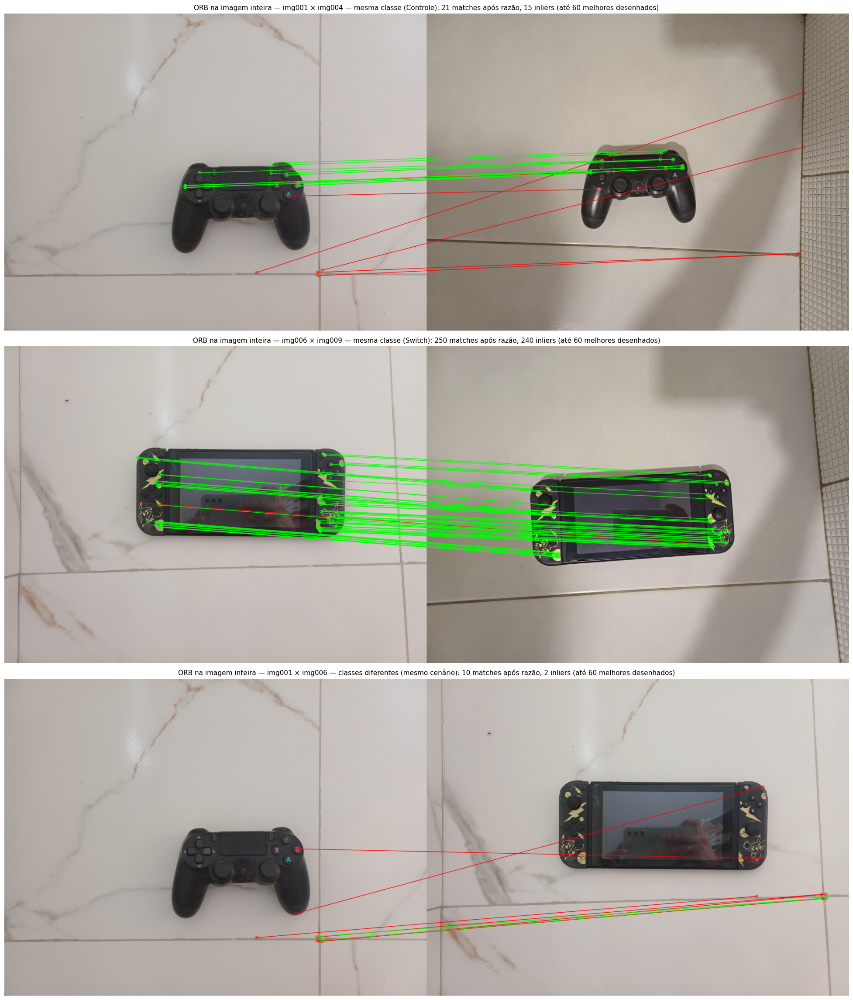

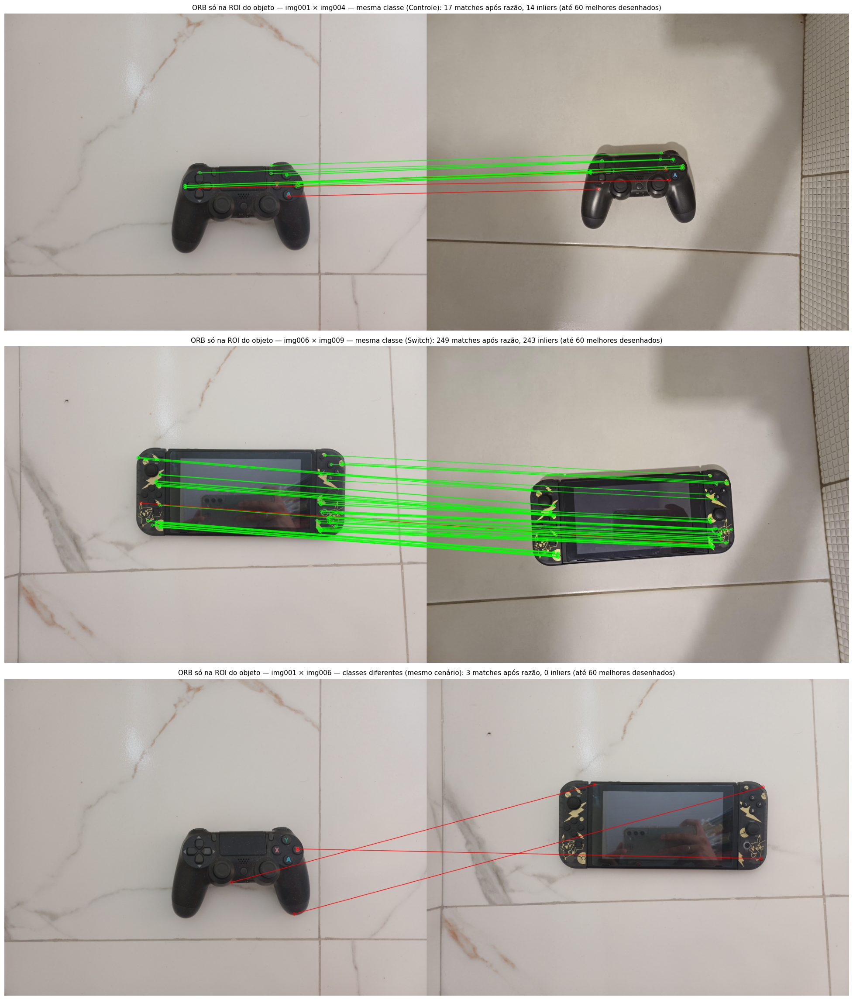

In [50]:
for usar_roi in (False, True):
    fig, axes = plt.subplots(3, 1, figsize=(20, 23))
    for ax, (i1, i2, tipo) in zip(axes, PARES):
        r = resultados[(i1, i2, usar_roi)]
        regiao = 'ORB só na ROI do objeto' if usar_roi else 'ORB na imagem inteira'
        desenhar(i1, i2, feats[(i1, usar_roi)], feats[(i2, usar_roi)], r, ax,
                 f"{regiao} — {i1} × {i2} — {tipo}: {r['razao']} matches após razão, {r['inliers']} inliers (até 60 melhores desenhados)")
    plt.tight_layout()
    plt.show()

Três pares são poucos para concluir algo sobre o descritor. Para verificar se o padrão se mantém, o matching é repetido para **todos os 45 pares** de imagens, com o ORB restrito à ROI e também na imagem inteira. Cada célula da matriz é o número de **inliers**. Os quadrantes superior-esquerdo e inferior-direito são pares da mesma classe; os outros dois, pares de classes diferentes.

**Cuidado com poucos inliers:** uma homografia tem 8 graus de liberdade e é definida por exatamente 4 correspondências. Se só 4 ou 5 matches passam no teste da razão, o RANSAC sempre encontra uma homografia que "explica" todos eles, mesmo que sejam aleatórios. Por isso, 4–5 inliers devem ser lidos como ruído. A última coluna da tabela de resumo usa a regra: **o vizinho de uma imagem é a que tem mais inliers com ela, desde que sejam pelo menos 10**; abaixo disso, o ORB "não decide".

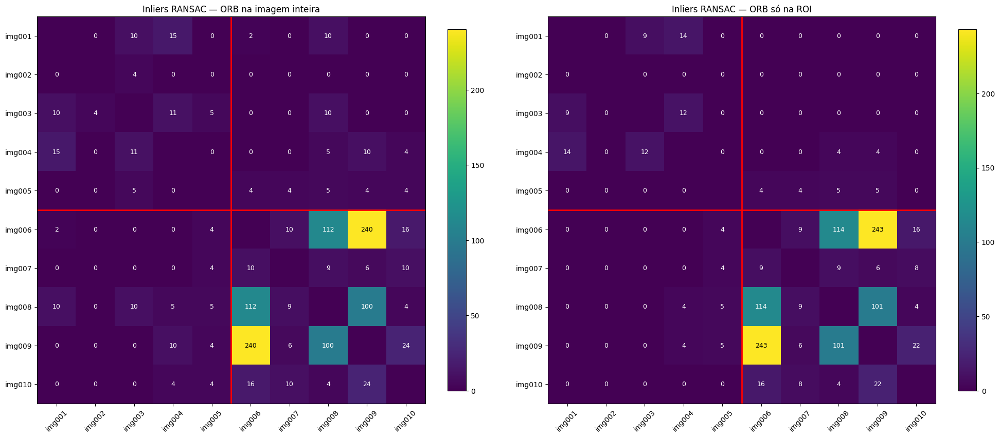

,Inliers médios — mesma classe (20 pares),Inliers médios — classes diferentes (25 pares),"Inliers médios — classes diferentes, MESMO cenário (5 pares)",Maior valor entre classes diferentes,Vizinho (≥ 10 inliers): certo | sem decisão | errado
Região,,,,,
imagem inteira,28.80,2.48,5.2,10,"8 | 2 (img002, img005) | 0"
só ROI,28.35,1.04,0.8,5,"7 | 3 (img002, img005, img007) | 0"


In [51]:
MIN_INLIERS = 10
def decisao_orb(M, minimo=MIN_INLIERS):
    # vizinho = imagem com mais inliers (>= minimo); devolve listas de acertos, sem decisão e erros
    ac, sem, err = [], [], []
    for a in range(10):
        linha = np.where(np.arange(10) == a, -1, M[a])
        v = int(np.argmax(linha))
        if linha[v] < minimo:
            sem.append(IDS[a])
        elif (a < 5) == (v < 5):
            ac.append(IDS[a])
        else:
            err.append(f'{IDS[a]}→{IDS[v]}')
    return ac, sem, err

def matriz_inliers(usar_roi):
    M = np.zeros((10, 10), int)
    for a in range(10):
        for b in range(a + 1, 10):
            M[a, b] = M[b, a] = casar(feats[(IDS[a], usar_roi)], feats[(IDS[b], usar_roi)])['inliers']
    return M

mats = {r: matriz_inliers(r) for r in (False, True)}
fig, axes = plt.subplots(1, 2, figsize=(20, 8.5))
resumo = []
for ax, usar_roi in zip(axes, (False, True)):
    M = mats[usar_roi]
    im = ax.imshow(M, cmap='viridis')
    for a in range(10):
        for b in range(10):
            if a != b:
                ax.text(b, a, M[a, b], ha='center', va='center', color='white' if M[a, b] < M.max() * 0.6 else 'black', fontsize=9)
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xticklabels(IDS, rotation=45); ax.set_yticklabels(IDS)
    ax.axhline(4.5, color='red', lw=2); ax.axvline(4.5, color='red', lw=2)
    ax.set_title(f"Inliers RANSAC — ORB {'só na ROI' if usar_roi else 'na imagem inteira'}")
    plt.colorbar(im, ax=ax, fraction=0.04)
    intra = [M[a, b] for a in range(10) for b in range(a + 1, 10) if (a < 5) == (b < 5)]
    inter = [M[a, b] for a in range(10) for b in range(a + 1, 10) if (a < 5) != (b < 5)]
    mesmo_cen = [M[a, a + 5] for a in range(5)]
    ac, sem, err = decisao_orb(M)
    resumo.append({'Região': 'só ROI' if usar_roi else 'imagem inteira',
                   'Inliers médios — mesma classe (20 pares)': np.mean(intra),
                   'Inliers médios — classes diferentes (25 pares)': np.mean(inter),
                   'Inliers médios — classes diferentes, MESMO cenário (5 pares)': np.mean(mesmo_cen),
                   'Maior valor entre classes diferentes': max(inter),
                   'Vizinho (≥ 10 inliers): certo | sem decisão | errado': f'{len(ac)} | {len(sem)} ({", ".join(sem)}) | {len(err)}'})
plt.tight_layout()
plt.show()
pd.DataFrame(resumo).set_index('Região')

**Interpretação — matching**

* **Sim, houve muito mais correspondências úteis entre imagens da mesma classe:**
   * **Switch × Switch (img006 × img009):** 592 matches brutos → 250 após a razão → **240 inliers** (96% dos matches que passaram na razão são geometricamente consistentes). As linhas verdes são quase paralelas e ligam cada estampa à mesma estampa na outra foto.
   * **Controle × Controle (img001 × img004):** bem menos: 133 → 21 → **15 inliers** (14 restrito à ROI), todos no direcional e nos botões. São poucos, mas corretos.
   * **Controle × Switch (img001 × img006):** 151 → 10 → **2 inliers** na imagem inteira, e **0** restrito à ROI.
* **Quantidade de matches não significou qualidade.** O par de **classes diferentes** teve **mais** matches brutos (151) que o par de controles (133): o *cross-check* sempre encontra algum vizinho mútuo, mesmo entre descritores sem relação. A distância de Hamming média também é pouco informativa nesse nível (56–59 bits nos dois casos). A diferença só aparece depois do **teste da razão** e, principalmente, do **RANSAC**: 1,3% dos matches brutos viraram inliers no par de classes diferentes, 11% no par de controles e 41% no par de Switches.
* **O fundo atrapalhou.** Na imagem inteira, os 2 "inliers" entre controle e Switch estão **no rejunte do piso**, que é o mesmo nas duas fotos. Na matriz completa, isso fica ainda mais claro: na imagem inteira, img003 × img008 e img004 × img009 (classes diferentes, mesmo cenário) chegam a **10 inliers**, todos nas pastilhas e rejuntes; restrito à ROI, esses mesmos pares têm 0 e 4. O maior valor entre classes diferentes cai de 10 (imagem inteira) para 5 (ROI), ou seja, para o nível de ruído.
* **Ângulo e escala atrapalharam mais que a iluminação:**
   * **Iluminação:** quase não pesou. img006 (luz natural) × img008 (noturna, bem mais escura) têm **114 inliers**, e img006 × img009 (sombra projetada) têm 243. Os testes binários do ORB comparam pares de pixels entre si, e uma mudança de brilho preserva o resultado da maioria dessas comparações.
   * **Ângulo:** a **vista oblíqua** do cenário 2 (img002, img007) praticamente não casa com nenhuma outra imagem (restrita à ROI, a img002 tem 0 inliers com todas). O ORB é invariante a rotação no plano e, pela pirâmide, a escala, mas **não a perspectiva**.
   * **Distância:** os closes do cenário 5 (img005, img010) também casam pouco (no máximo 22 inliers na ROI). A escala muda cerca de 3×, e o controle tem superfície curva e reflexos.
* **Na matriz completa:** a média de inliers é **28,4 entre pares da mesma classe** e **1,0 entre classes diferentes** (ROI). Com a regra "vizinho = mais inliers, mínimo de 10", o ORB **não errou nenhuma imagem**: acertou 7 e ficou "sem decisão" em 3 (img002, img005, img007), justamente as vistas oblíquas e próximas. Na imagem inteira o resultado foi 8 acertos e 2 sem decisão, mas parte desses inliers vem do fundo, como mostrado acima.
* **O que preserva e o que perde:** o matching com verificação geométrica preserva a **estrutura do objeto** (quais detalhes existem e como estão dispostos entre si). Por isso é o único descritor que reconheceu o mesmo objeto em cenários diferentes. Ele perde a capacidade de generalizar: ele reconhece **este** Switch com **estas** estampas, e não "consoles" em geral. Além disso, depende de vistas parecidas e de detalhes com contraste.

### 3.4 Teste de robustez

Uma imagem de cada classe (ROI de **img006** — Switch — e de **img001** — Controle, com 40 px de margem) recebe três transformações geradas no notebook:

| Transformação | Parâmetros |
|---|---|
| Rotação leve | 15° em torno do centro (`cv2.warpAffine`, borda replicada) |
| Redução de contraste | $I' = 0{,}4\,(I - \bar I) + \bar I$ — o contraste cai para 40% |
| Borramento leve | Gaussiano 7×7, σ = 2 |

Como a transformação é **conhecida**, dá para medir não só quantos matches existem, mas **quantos estão certos**: cada keypoint da original é levado pela transformação verdadeira até a imagem modificada, e o match é considerado **correto** se cair a menos de 3 px do ponto esperado. Assim, a "qualidade" deixa de ser uma estimativa e passa a ser uma medida exata.

In [52]:
def recorte_margem(iid, m=40):
    x, y, w, h = ROI[iid]
    return cinza[iid][max(y-m, 0):y+h+m, max(x-m, 0):x+w+m]

def transformar(img, tipo):
    h, w = img.shape
    if tipo == 'Rotação 15°':
        A = cv2.getRotationMatrix2D((w / 2, h / 2), 15, 1.0)
        return cv2.warpAffine(img, A, (w, h), borderMode=cv2.BORDER_REPLICATE), A
    A = np.float32([[1, 0, 0], [0, 1, 0]])        # identidade: a geometria não muda
    if tipo == 'Contraste 40%':
        return np.clip(0.4 * (img.astype(float) - img.mean()) + img.mean(), 0, 255).astype(np.uint8), A
    if tipo == 'Borramento σ=2':
        return cv2.GaussianBlur(img, (7, 7), 2), A
    return img.copy(), A

TRANSF = ['Sem alteração', 'Rotação 15°', 'Contraste 40%', 'Borramento σ=2']
tab_rob, vis_rob = [], {}
for iid in ['img006', 'img001']:
    base = recorte_margem(iid)
    kp0, d0 = orb.detectAndCompute(base, None)
    for t in TRANSF:
        mod, A = transformar(base, t)
        kp1, d1 = orb.detectAndCompute(mod, None)
        r = casar((kp0, d0), (kp1, d1))
        corretos = np.zeros(len(r['bons']), bool)
        for k, m in enumerate(r['bons']):
            esperado = A @ np.array([*kp0[m.queryIdx].pt, 1.0])
            corretos[k] = np.linalg.norm(esperado - np.array(kp1[m.trainIdx].pt)) < 3
        vis_rob[(iid, t)] = (base, mod, kp0, kp1, r, corretos)
        tab_rob.append({'Imagem': iid, 'Transformação': t, 'Contraste (DP)': mod.std(),
                        'Keypoints original': len(kp0), 'Keypoints modificada': len(kp1),
                        'Matches brutos': r['brutos'], 'Após razão': r['razao'],
                        'Hamming médio (razão)': r['hamming_razao'],
                        'Corretos (< 3 px)': int(corretos.sum()),
                        'Precisão (%)': 100 * corretos.mean() if len(corretos) else np.nan,
                        'Keypoints recuperados (%)': 100 * corretos.sum() / len(kp0)})
tab_rob = pd.DataFrame(tab_rob).set_index(['Imagem', 'Transformação'])
tab_rob

Contraste (DP)  Keypoints original  Keypoints modificada  Matches brutos  Após razão  Hamming médio (razão)  Corretos (< 3 px)  Precisão (%)  Keypoints recuperados (%)
Imagem Transformação                                                                                                                                                                          
img006 Sem alteração            62.61                1040                  1040            1040        1040                   0.00               1040        100.00                     100.00
       Rotação 15°              63.06                1040                   738             536         498                  23.45                482         96.79                      46.35
       Contraste 40%            25.04                1040                   509             499         544                  11.86                535         98.35                      51.44
       Borramento σ=2           61.35                1040                   387             306         301                  22.59                288         95.68                      27.69
img001 Sem alteração            60.42                 266                   266             266         266                   0.00                266        100.00                     100.00
       Rotação 15°              60.51                 266                   204             154         156                  25.79                147         94.23                      55.26
       Contraste 40%            24.17                 266                    52              51          59                  21.86                 57         96.61                      21.43
       Borramento σ=2           59.89                 266                    58              46          60                  29.13                 52         86.67                      19.55

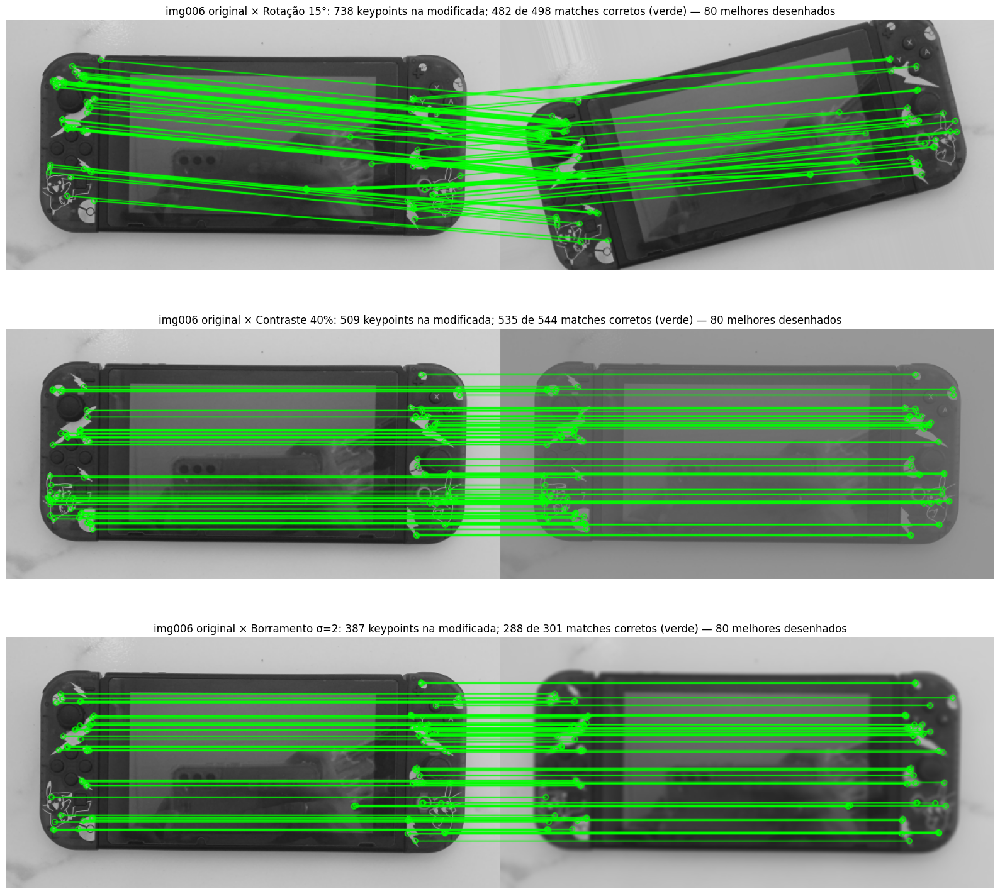

In [53]:
fig, axes = plt.subplots(3, 1, figsize=(16, 15))
for ax, t in zip(axes, TRANSF[1:]):
    base, mod, kp0, kp1, r, corretos = vis_rob[('img006', t)]
    bons = r['bons'][:80]
    ok = [m for m, c in zip(bons, corretos[:80]) if c]
    err = [m for m, c in zip(bons, corretos[:80]) if not c]
    b3, m3 = cv2.cvtColor(base, cv2.COLOR_GRAY2RGB), cv2.cvtColor(mod, cv2.COLOR_GRAY2RGB)
    viz = cv2.drawMatches(b3, kp0, m3, kp1, err, None, matchColor=(255, 0, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    viz = cv2.drawMatches(b3, kp0, m3, kp1, ok, viz, matchColor=(0, 255, 0),
                          flags=cv2.DrawMatchesFlags_DRAW_OVER_OUTIMG | cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    ax.imshow(viz); ax.axis('off')
    ax.set_title(f'img006 original × {t}: {len(kp1)} keypoints na modificada; {int(corretos.sum())} de {len(corretos)} matches corretos (verde) — 80 melhores desenhados')
plt.tight_layout()
plt.show()

**Interpretação — robustez**

* **O número de keypoints mudou?** Sim, e caiu em todas as transformações. Para o Switch (1.040 keypoints na original): **−29%** com a rotação (738), **−51%** com a redução de contraste (509) e **−63%** com o borramento (387). Para o controle (266 na original): −23%, **−80%** e −78%.
* **A qualidade dos matches caiu?** Muito pouco. Dos matches que sobreviveram ao teste da razão, entre **96% e 98% estavam corretos** no Switch (erro < 3 px em relação à posição verdadeira), e entre **87% e 97%** no controle. A perda está na **quantidade**: a fração de keypoints da original reencontrada corretamente cai para 46% (rotação), 51% (contraste) e 28% (borramento) no Switch.
* **Até que ponto o ORB se mostrou robusto?** O resultado separa as duas etapas do ORB:
   * **O descritor é robusto.** Com contraste reduzido, a distância de Hamming média foi a menor de todas (11,9 bits). Uma mudança linear de contraste não altera o sinal das diferenças entre pixels, que é exatamente o que os testes binários do BRIEF medem. Na rotação, a orientação calculada pelo centroide compensou o giro, e a precisão continuou em 97%.
   * **O detector é sensível.** O FAST usa um limiar **absoluto** de intensidade, então reduzir o contraste para 40% elimina todos os cantos cujo contraste original era menor que cerca de 2,5× esse limiar. O borramento é a pior transformação, porque remove justamente as altas frequências que definem um canto.
* **O controle sofre muito mais.** A redução de contraste derrubou 80% dos keypoints do controle e 51% dos do Switch. É o mesmo padrão das Atividades 1 e 3: os detalhes do controle já têm pouco contraste e são os primeiros a desaparecer.
* *Observação:* em algumas linhas, "Após razão" é maior que "Matches brutos". Não é um erro: são dois filtros independentes (o *cross-check* exige reciprocidade; o teste da razão compara o 1º e o 2º vizinho), e um match pode passar num e falhar no outro.

---
## Parte 4 — Análise de textura: GLCM e LBP

### 4.1 Seleção das regiões

Nenhum dos dois objetos tem uma textura "de superfície" forte como madeira, tecido ou pedra: o **controle** é plástico preto fosco quase liso, e o que o **Switch** tem de mais "textural" são as estampas douradas — que são desenhos, não microtextura. Por isso foram usados **recortes (patches)** da superfície de cada objeto, em dois cenários por classe, e dois **patches de fundo** como referência de textura forte:

| Patch | Imagem | Conteúdo |
|---|---|---|
| A1 | img001 (cenário 1) | Corpo do controle (empunhadura esquerda) |
| A2 | img005 (cenário 5) | Corpo do controle (empunhadura direita) |
| B1 | img006 (cenário 1) | Joy-Con esquerdo com estampa |
| B2 | img010 (cenário 5) | Joy-Con esquerdo com estampa |
| F1 | img001 (cenário 1) | Fundo: cerâmica lisa (sem veio) |
| F2 | img005 (cenário 5) | Fundo: tapete com relevo |

Os patches são recortados da **imagem original (8000×6000)** e redimensionados para **256×256** com `INTER_AREA`, para que todos tenham o mesmo número de pixels. Uma limitação importante: como os objetos estão a distâncias diferentes, a mesma área física não corresponde ao mesmo número de pixels nos dois cenários — a escala da textura não é exatamente igual entre A1 e A2 (nem entre B1 e B2).

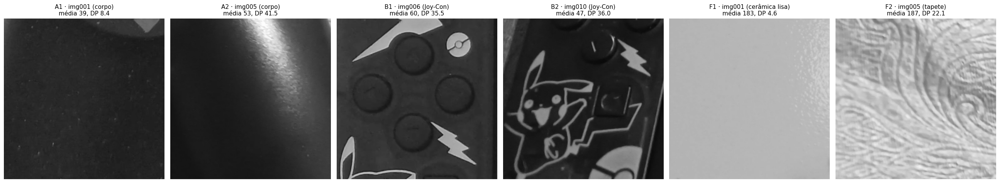

In [54]:
# (x, y, largura, altura) na resolução de trabalho; o recorte é feito na original (× ESCALA)
PATCHES = {
    'A1 · img001 (corpo)': ('img001', (418, 452, 62, 62)),
    'A2 · img005 (corpo)': ('img005', (720, 480, 130, 130)),
    'B1 · img006 (Joy-Con)': ('img006', (326, 330, 65, 65)),
    'B2 · img010 (Joy-Con)': ('img010', (65, 430, 130, 130)),
    'F1 · img001 (cerâmica lisa)': ('img001', (180, 120, 130, 130)),
    'F2 · img005 (tapete)': ('img005', (860, 60, 130, 130)),
}
originais = {iid: cv2.imread(meta.loc[iid, 'caminho'], cv2.IMREAD_GRAYSCALE) for iid in {v[0] for v in PATCHES.values()}}
patches = {}
for nome, (iid, (x, y, w, h)) in PATCHES.items():
    X, Y, W, H = [int(round(v * ESCALA)) for v in (x, y, w, h)]
    patches[nome] = cv2.resize(originais[iid][Y:Y+H, X:X+W], (256, 256), interpolation=cv2.INTER_AREA)
del originais

fig, axes = plt.subplots(1, 6, figsize=(26, 5))
for ax, (nome, p) in zip(axes, patches.items()):
    ax.imshow(p, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'{nome}\nmédia {p.mean():.0f}, DP {p.std():.1f}', fontsize=11); ax.axis('off')
plt.tight_layout()
plt.show()

### 4.2 GLCM

A **GLCM** (*Gray-Level Co-occurrence Matrix*) conta com que frequência um pixel de nível *i* aparece a uma distância *d*, numa direção θ, de um pixel de nível *j*. Diferente do histograma, ela **preserva a relação espacial entre pares de pixels**. Dela se extraem:

| Propriedade | Fórmula | Interpretação |
|---|---|---|
| **contrast** | $\sum P(i,j)(i-j)^2$ | variação local entre vizinhos; alto = textura áspera / bordas |
| **homogeneity** | $\sum \frac{P(i,j)}{1+(i-j)^2}$ | proximidade da diagonal; alto = vizinhos com níveis parecidos (liso) |
| **energy** | $\sqrt{\sum P(i,j)^2}$ | uniformidade; alto = poucos pares de níveis dominam (padrão simples/repetitivo) |
| **correlation** | $\sum \frac{(i-\mu_i)(j-\mu_j)P(i,j)}{\sigma_i\sigma_j}$ | dependência linear entre vizinhos; alto = estruturas maiores que *d* (variação suave e previsível) |

**Quantização:** os patches são reduzidos de 256 para **32 níveis** (`patch // 8`) antes da GLCM. Com 256 níveis a matriz teria 65.536 células para ~65 mil pares de pixels: ficaria esparsa e dominada por ruído; com 32 níveis (1.024 células) as estatísticas ficam estáveis, e a Atividade 1 já mostrou que 32 níveis preservam a aparência do objeto.

**Parâmetros:** distâncias **d = 1 e d = 4** px, ângulos **0°, 45°, 90° e 135°**, matriz simétrica e normalizada. A tabela principal usa a média dos 4 ângulos (descritor invariante à orientação); a tabela seguinte mostra o *contrast* por ângulo, para verificar se há direção preferencial.

In [55]:
DIST = [1, 4]
ANG = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
PROPS = ['contrast', 'homogeneity', 'energy', 'correlation']

def glcm_props(p, niveis=32):
    q = (p // (256 // niveis)).astype(np.uint8)
    G = graycomatrix(q, distances=DIST, angles=ANG, levels=niveis, symmetric=True, normed=True)
    return {prop: graycoprops(G, prop) for prop in PROPS}, G      # cada prop: matriz (distâncias × ângulos)

glcm, glcm_mats, por_angulo = [], {}, []
for nome, p in patches.items():
    pr, G = glcm_props(p)
    glcm_mats[nome] = G
    linha = {'Patch': nome}
    for di, d in enumerate(DIST):
        for prop in PROPS:
            linha[(f'd={d}', prop)] = pr[prop][di].mean()
    glcm.append(linha)
    por_angulo.append({'Patch': nome, **{f'contrast d=1, {int(np.degrees(a))}°': pr['contrast'][0, k] for k, a in enumerate(ANG)},
                       'anisotropia (máx/mín)': pr['contrast'][0].max() / pr['contrast'][0].min()})
tab_glcm = pd.DataFrame(glcm).set_index('Patch')
tab_glcm.columns = pd.MultiIndex.from_tuples(tab_glcm.columns)
display(tab_glcm)
pd.DataFrame(por_angulo).set_index('Patch')

d=1                                     d=4                               
                            contrast homogeneity energy correlation contrast homogeneity energy correlation
Patch                                                                                                      
A1 · img001 (corpo)             0.21        0.91   0.53        0.91     0.46        0.84   0.47        0.80
A2 · img005 (corpo)             0.30        0.92   0.42        0.99     0.91        0.85   0.40        0.98
B1 · img006 (Joy-Con)           2.47        0.87   0.43        0.94     9.86        0.75   0.36        0.75
B2 · img010 (Joy-Con)           2.03        0.81   0.42        0.95    12.31        0.67   0.36        0.70
F1 · img001 (cerâmica lisa)     0.10        0.95   0.74        0.89     0.20        0.92   0.72        0.77
F2 · img005 (tapete)            1.26        0.69   0.18        0.92     6.67        0.40   0.12        0.57

,"contrast d=1, 0°","contrast d=1, 45°","contrast d=1, 90°","contrast d=1, 135°",anisotropia (máx/mín)
Patch,,,,,
A1 · img001 (corpo),0.18,0.26,0.18,0.24,1.46
A2 · img005 (corpo),0.21,0.26,0.27,0.45,2.18
B1 · img006 (Joy-Con),1.49,3.50,2.12,2.78,2.35
B2 · img010 (Joy-Con),1.60,3.09,1.26,2.18,2.45
F1 · img001 (cerâmica lisa),0.09,0.11,0.08,0.13,1.54
F2 · img005 (tapete),0.75,1.05,1.10,2.14,2.88


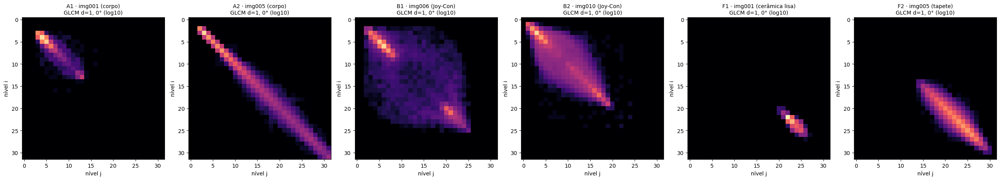

In [56]:
fig, axes = plt.subplots(1, 6, figsize=(26, 4.8))
for ax, (nome, G) in zip(axes, glcm_mats.items()):
    ax.imshow(np.log10(G[:, :, 0, 0] + 1e-5), cmap='magma', vmin=-5, vmax=0)
    ax.set_title(f'{nome}\nGLCM d=1, 0° (log10)', fontsize=10)
    ax.set_xlabel('nível j'); ax.set_ylabel('nível i')
plt.tight_layout()
plt.show()

**Interpretação — GLCM**

* **Corpo do controle (A1, A2):** *contrast* muito baixo (0,21 e 0,30 para d = 1), *homogeneity* alta (0,91–0,92) e *correlation* alta (0,91 e 0,99). É o perfil de uma superfície lisa, onde vizinhos têm quase o mesmo nível. A A2 tem *correlation* de 0,99 porque o reflexo especular cria um **gradiente suave**: os níveis variam, mas de forma previsível de um pixel para o seguinte. É também por isso que o *contrast* dela dobra com d = 4 (0,91).
* **Joy-Con (B1, B2):** *contrast* cerca de **10 vezes maior** (2,47 e 2,03 para d = 1; 9,86 e 12,31 para d = 4), por causa dos saltos entre o plástico preto e a estampa clara. A *correlation* cai de ~0,95 (d = 1) para ~0,72 (d = 4): as estruturas têm poucos pixels de largura, então, a 4 px de distância, os vizinhos já estão do outro lado de uma borda.
* **Fundos de referência:** a cerâmica lisa (F1) é a superfície mais uniforme de todas (*contrast* 0,10, *energy* 0,74, a maior). O **tapete (F2)** é a única textura "de verdade": *homogeneity* 0,69 → 0,40 e *energy* 0,18 → 0,12 (as menores), *correlation* 0,57 com d = 4. São muitos níveis, combinados de forma irregular.
* **Ângulos:** o controle e a cerâmica são quase **isotrópicos** (razão máx/mín do *contrast* entre os 4 ângulos ≈ 1,5). Nos Joy-Cons, o *contrast* é máximo em **45°** (3,50 e 3,09): os raios das estampas são diagonais. O tapete é o mais anisotrópico (2,88), com o relevo orientado na direção de 135°.
* **A GLCM separou as classes?** Em parte. Entre os patches, as distâncias GLCM são 3,0 (A1 × A2) e 1,2 (B1 × B2), contra 3,9 em média entre classes diferentes. Mas é preciso cuidado com o que está sendo medido: o *contrast* alto do Joy-Con vem da **estampa**, que é um desenho, e não da textura do plástico. Um patch do Joy-Con sem estampa teria valores parecidos com os do controle. Além disso, o tapete (F2) tem *contrast* mais próximo do Joy-Con do que do controle.
* **O que preserva e o que perde:** a GLCM preserva **relações entre pares de pixels** a uma distância e direção: aspereza, uniformidade e orientação. Ela perde a **forma** das estruturas, e o resultado depende fortemente de onde o patch é recortado.

### 4.3 LBP

O **LBP** (*Local Binary Pattern*) compara cada pixel com seus *P* vizinhos num círculo de raio *R*: vizinho ≥ centro → 1, senão 0, gerando um código binário que descreve a **microestrutura** local (ponto, borda, canto, região plana). Foi usado **P = 8, R = 1** com o método **`uniform`** (invariante à rotação): os códigos com no máximo 2 transições 0↔1 são *uniformes* e recebem um rótulo de 0 a 8 conforme o número de 1s; todos os demais caem num único rótulo 9 (não uniforme). Interpretação dos rótulos:

* **0** — centro mais claro que todos os vizinhos (ponto claro/pico);
* **1–3** — bordas e cantos no lado claro;
* **4** — borda reta (metade dos vizinhos acima, metade abaixo);
* **5–7** — bordas e cantos no lado escuro;
* **8** — todos os vizinhos ≥ centro: região plana ou ponto escuro;
* **9** — padrões não uniformes: ruído ou microtextura irregular.

O histograma normalizado (10 bins) é o descritor. A comparação entre patches usa a distância **qui-quadrado** $\chi^2 = \frac{1}{2}\sum \frac{(h_1-h_2)^2}{h_1+h_2}$.

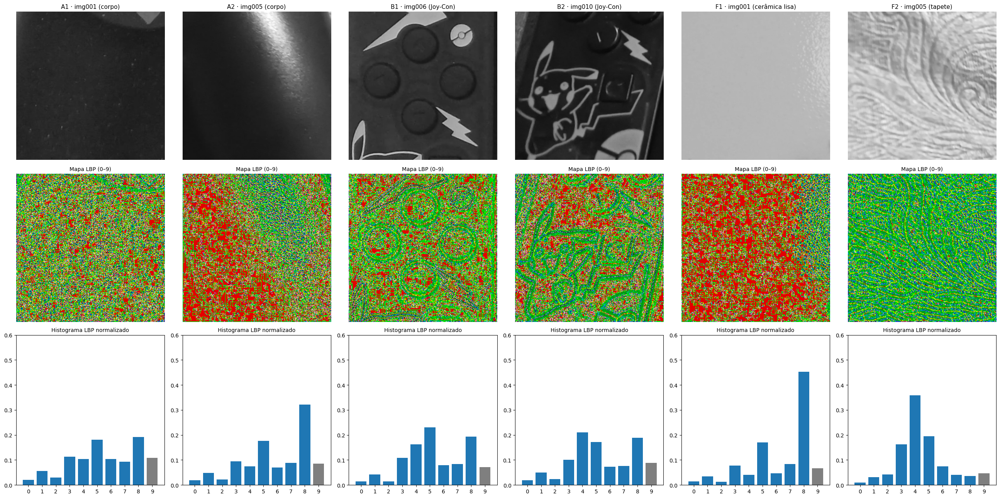

,LBP 0,LBP 1,LBP 2,LBP 3,LBP 4,LBP 5,LBP 6,LBP 7,LBP 8,LBP 9,Planos (8) + pico (0),Bordas (3–5),Não uniformes (9)
A1 · img001 (corpo),0.02,0.06,0.03,0.11,0.10,0.18,0.10,0.09,0.19,0.11,0.21,0.40,0.11
A2 · img005 (corpo),0.02,0.05,0.02,0.09,0.07,0.18,0.07,0.09,0.32,0.09,0.34,0.35,0.09
B1 · img006 (Joy-Con),0.01,0.04,0.02,0.11,0.16,0.23,0.08,0.08,0.19,0.07,0.21,0.50,0.07
B2 · img010 (Joy-Con),0.02,0.05,0.02,0.10,0.21,0.17,0.07,0.08,0.19,0.09,0.21,0.48,0.09
F1 · img001 (cerâmica lisa),0.01,0.03,0.01,0.08,0.04,0.17,0.05,0.08,0.45,0.07,0.47,0.29,0.07
F2 · img005 (tapete),0.01,0.03,0.04,0.16,0.36,0.20,0.07,0.04,0.04,0.05,0.05,0.72,0.05


In [57]:
P_LBP, R_LBP = 8, 1
def lbp_hist(img):
    lbp = local_binary_pattern(img, P_LBP, R_LBP, method='uniform')
    h, _ = np.histogram(lbp, bins=np.arange(P_LBP + 3), density=True)
    return lbp, h

def chi2(a, b):
    return 0.5 * np.sum((a - b)**2 / (a + b + 1e-10))

lbps = {nome: lbp_hist(p) for nome, p in patches.items()}
fig, axes = plt.subplots(3, 6, figsize=(26, 13))
for col, (nome, (lbp, h)) in enumerate(lbps.items()):
    axes[0, col].imshow(patches[nome], cmap='gray', vmin=0, vmax=255); axes[0, col].set_title(nome, fontsize=11)
    axes[1, col].imshow(lbp, cmap='nipy_spectral', vmin=0, vmax=9); axes[1, col].set_title('Mapa LBP (0–9)', fontsize=10)
    axes[0, col].axis('off'); axes[1, col].axis('off')
    axes[2, col].bar(range(10), h, color=['tab:blue'] * 9 + ['tab:gray'])
    axes[2, col].set_ylim(0, 0.6); axes[2, col].set_xticks(range(10))
    axes[2, col].set_title('Histograma LBP normalizado', fontsize=10)
plt.tight_layout()
plt.show()

tab_lbp = pd.DataFrame({nome: h for nome, (_, h) in lbps.items()}, index=[f'LBP {k}' for k in range(10)]).T
tab_lbp['Planos (8) + pico (0)'] = tab_lbp['LBP 8'] + tab_lbp['LBP 0']
tab_lbp['Bordas (3–5)'] = tab_lbp[['LBP 3', 'LBP 4', 'LBP 5']].sum(axis=1)
tab_lbp['Não uniformes (9)'] = tab_lbp['LBP 9']
tab_lbp

Para checar se as duas técnicas concordam, as matrizes abaixo mostram a distância entre todos os pares de patches: à esquerda, **χ² entre histogramas LBP**; à direita, **distância euclidiana entre os vetores GLCM** (8 propriedades: 4 × 2 distâncias, padronizadas pelo z-score, já que contraste e energia têm escalas muito diferentes). Se a textura separasse as classes, A1–A2 e B1–B2 deveriam ser pares próximos, e Ax–Bx, distantes.

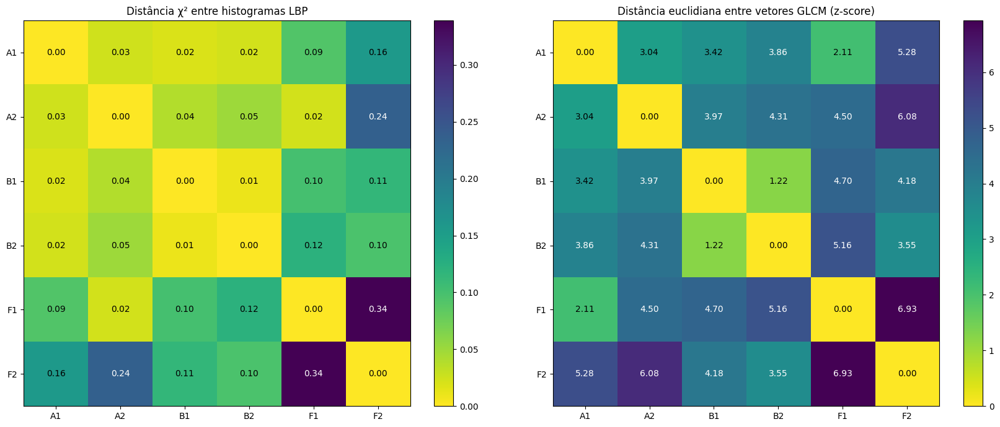

,LBP (χ²),GLCM (euclidiana)
A1 × A2 (mesma classe),0.03,3.04
B1 × B2 (mesma classe),0.01,1.22
média A × B (classes diferentes),0.03,3.89
"A1 × B1 (classes dif., mesmo cenário)",0.02,3.42
"A2 × B2 (classes dif., mesmo cenário)",0.05,4.31


In [58]:
nomes = list(patches)
vet_glcm = tab_glcm.values
vet_glcm = (vet_glcm - vet_glcm.mean(0)) / vet_glcm.std(0)
D_lbp = np.array([[chi2(lbps[a][1], lbps[b][1]) for b in nomes] for a in nomes])
D_glcm = np.array([[np.linalg.norm(vet_glcm[i] - vet_glcm[j]) for j in range(6)] for i in range(6)])
curtos = [n.split(' ·')[0] for n in nomes]
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, D, tit in zip(axes, (D_lbp, D_glcm), ('Distância χ² entre histogramas LBP', 'Distância euclidiana entre vetores GLCM (z-score)')):
    im = ax.imshow(D, cmap='viridis_r')
    for i in range(6):
        for j in range(6):
            ax.text(j, i, f'{D[i, j]:.2f}', ha='center', va='center', color='white' if D[i, j] > D.max() * 0.5 else 'black')
    ax.set_xticks(range(6)); ax.set_yticks(range(6)); ax.set_xticklabels(curtos); ax.set_yticklabels(curtos)
    ax.set_title(tit); plt.colorbar(im, ax=ax, fraction=0.045)
plt.tight_layout()
plt.show()

idx = {c: k for k, c in enumerate(curtos)}
def d(D, a, b): return D[idx[a], idx[b]]
pd.DataFrame({
    'LBP (χ²)': [d(D_lbp, 'A1', 'A2'), d(D_lbp, 'B1', 'B2'), np.mean([d(D_lbp, a, b) for a in ('A1', 'A2') for b in ('B1', 'B2')]),
                 d(D_lbp, 'A1', 'B1'), d(D_lbp, 'A2', 'B2')],
    'GLCM (euclidiana)': [d(D_glcm, 'A1', 'A2'), d(D_glcm, 'B1', 'B2'), np.mean([d(D_glcm, a, b) for a in ('A1', 'A2') for b in ('B1', 'B2')]),
                          d(D_glcm, 'A1', 'B1'), d(D_glcm, 'A2', 'B2')],
}, index=['A1 × A2 (mesma classe)', 'B1 × B2 (mesma classe)', 'média A × B (classes diferentes)',
          'A1 × B1 (classes dif., mesmo cenário)', 'A2 × B2 (classes dif., mesmo cenário)'])

**Interpretação — LBP**

* **O LBP capturou microestruturas?** Capturou, mas as mais relevantes estão no **fundo**:
   * **Tapete (F2):** 36% de código 4 (borda reta) e 72% de bordas no total (códigos 3–5). É o relevo.
   * **Cerâmica (F1):** 45% de código 8 (região plana).
   * **Controle:** a A2 tem 32% de código 8 (plástico liso). A **A1** tem a maior fração de códigos **não uniformes** (11%), e seu mapa LBP é um "sal e pimenta" sem estrutura. No plástico preto quase uniforme, os padrões de 1 px vêm do **ruído do sensor e do JPEG** (e de grãos de poeira), não de uma textura real.
   * **Joy-Cons:** o mapa mostra os **contornos das estampas e dos botões** como faixas de códigos de borda, com o interior plano. O histograma tem 48–50% de bordas.
* **As classes ficaram mais separáveis por textura?** Pouco. As distâncias χ² entre os patches dos objetos são todas muito pequenas (0,01 a 0,05). **A1 × B1 (0,02, classes diferentes) é menor que A1 × A2 (0,03, mesma classe)**. O LBP com R = 1 olha para a vizinhança de 1 pixel, e nessa escala os dois objetos são "plástico com algumas bordas". O histograma também perde **onde** estão as bordas: o contorno de um raio e o de um botão geram os mesmos códigos.
* **GLCM e LBP foram coerentes?** Em parte:
   * As duas concordam que **B1 e B2 são o par mais parecido** (χ² = 0,01; distância GLCM = 1,2) e que o **tapete é diferente de tudo**.
   * Elas discordam sobre controle × Switch: a GLCM separa razoavelmente (média de 3,9 contra 3,0 e 1,2 dentro das classes) e o LBP não. Isso acontece porque a principal diferença entre o plástico liso e a estampa é a **amplitude** do salto de intensidade, e o LBP é **invariante à amplitude** (só registra se o vizinho é maior ou menor). A GLCM, que mede (i − j)², registra essa diferença.
* **Conclusão da etapa:** como esperado na hipótese, **o dataset não é textural**. A textura mais forte das imagens está no **fundo** (tapete, veios, pastilhas). Nos objetos, GLCM e LBP medem basicamente quanto de estampa ou borda há no patch. O teste da Parte 5.1 confirma isso: aplicados à imagem inteira, GLCM e LBP encontram como "mais parecida" a foto **do mesmo cenário** em 9 e 10 dos 10 casos.

---
## Parte 5 — Síntese integradora

### 5.1 Verificação quantitativa: qual descritor reconhece a classe?

As partes anteriores avaliaram cada descritor separadamente, com critérios diferentes. Para compará-los **na mesma régua**, cada um é usado como entrada de um classificador muito simples, o **vizinho mais próximo (1-NN) com validação *leave-one-out***: para cada uma das 10 imagens, procura-se, entre as outras 9, a mais parecida segundo o descritor; acerta se ela for da mesma classe. O acaso daria cerca de 4/10 (dos 9 vizinhos possíveis, só 4 são da mesma classe).

Descritores testados, sempre na imagem inteira **e** só na ROI do objeto:

| Descritor | Vetor / similaridade |
|---|---|
| Estatística global | (média, desvio padrão, entropia), padronizados pelo z-score; distância euclidiana |
| Histograma de intensidade | 32 bins normalizados; distância χ² |
| Histograma de cor HSV | 8 (H) × 4 (S) × 4 (V) bins normalizados; distância χ² |
| GLCM | 4 propriedades × 2 distâncias (média dos ângulos), 32 níveis, z-score; euclidiana |
| LBP | histograma uniforme P=8, R=1; distância χ² |
| ORB + matching | número de inliers RANSAC (matriz da Parte 3.3); vizinho = imagem com mais inliers, se ≥ 10 (senão, "sem decisão") |

A coluna **"Erros com vizinho do MESMO cenário"** conta quantos erros consistiram em escolher justamente a foto da outra classe tirada no mesmo cenário (ex.: img001 → img006). Ela mostra se o descritor está reconhecendo o **objeto** ou a **cena**.

> Com 10 imagens o resultado tem pouco poder estatístico (cada erro vale 10 pontos percentuais) e não substitui um conjunto de teste de verdade; ele serve para **confirmar ou desmentir** as conclusões qualitativas das partes anteriores.

In [59]:
def vetores(iid, usar_roi):
    g = recorte_roi(cinza[iid], iid) if usar_roi else cinza[iid]
    c = recorte_roi(cor[iid], iid) if usar_roi else cor[iid]
    s = estatisticas(g)
    hsv = cv2.cvtColor(c, cv2.COLOR_RGB2HSV)
    h_hsv = cv2.calcHist([hsv], [0, 1, 2], None, [8, 4, 4], [0, 180, 0, 256, 0, 256]).ravel()
    q = (g // 8).astype(np.uint8)
    G = graycomatrix(q, DIST, ANG, levels=32, symmetric=True, normed=True)
    return {'Estatística global': np.array([s['Média'], s['Desvio padrão'], s['Entropia (bits)']]),
            'Histograma de intensidade': hist_norm(g, bins=32),
            'Histograma de cor HSV': h_hsv / h_hsv.sum(),
            'GLCM': np.concatenate([graycoprops(G, p).mean(axis=1) for p in PROPS]),
            'LBP': lbp_hist(g)[1]}

DIST_TIPO = {'Estatística global': 'z', 'Histograma de intensidade': 'chi2', 'Histograma de cor HSV': 'chi2', 'GLCM': 'z', 'LBP': 'chi2'}
classes = np.array([meta.loc[i, 'Classe'] for i in IDS])

def loo_1nn(D):
    D = D.astype(float).copy(); np.fill_diagonal(D, np.inf)
    viz = D.argmin(axis=1)
    return (classes[viz] == classes).sum(), [f'{IDS[a]}→{IDS[viz[a]]}' for a in range(10) if classes[viz[a]] != classes[a]]

linhas = []
for usar_roi in (False, True):
    V = [vetores(i, usar_roi) for i in IDS]
    for desc, tipo in DIST_TIPO.items():
        X = np.array([v[desc] for v in V])
        if tipo == 'z':
            X = (X - X.mean(0)) / (X.std(0) + 1e-12)
            D = np.linalg.norm(X[:, None] - X[None], axis=2)
        else:
            D = np.array([[chi2(a, b) for b in X] for a in X])
        ac, erros = loo_1nn(D)
        linhas.append({'Descritor': desc, 'Região': 'só ROI' if usar_roi else 'imagem inteira', 'Acertos': ac,
                       'Sem decisão': 0, 'Erros': 10 - ac,
                       'Erros com vizinho do MESMO cenário': sum(int(e[3:6]) % 5 == int(e[-3:]) % 5 for e in erros),
                       'Erros (imagem → vizinho de outra classe)': ', '.join(erros) or '—'})
    ac, sem, erros = decisao_orb(mats[usar_roi])      # mais inliers = mais próximo (mínimo de 10)
    linhas.append({'Descritor': 'ORB + matching', 'Região': 'só ROI' if usar_roi else 'imagem inteira', 'Acertos': len(ac),
                   'Sem decisão': len(sem), 'Erros': len(erros),
                   'Erros com vizinho do MESMO cenário': sum(int(e[3:6]) % 5 == int(e[-3:]) % 5 for e in erros),
                   'Erros (imagem → vizinho de outra classe)': ', '.join(erros) or f'— (sem decisão: {", ".join(sem)})'})
tab_1nn = pd.DataFrame(linhas).set_index(['Descritor', 'Região'])
tab_1nn

,,Acertos,Sem decisão,Erros,Erros com vizinho do MESMO cenário,Erros (imagem → vizinho de outra classe)
Descritor,Região,,,,,
Estatística global,imagem inteira,1,0,9,6,"img001→img007, img002→img006, img003→img008, i..."
Histograma de intensidade,imagem inteira,0,0,10,9,"img001→img006, img002→img007, img003→img008, i..."
Histograma de cor HSV,imagem inteira,0,0,10,6,"img001→img009, img002→img006, img003→img008, i..."
GLCM,imagem inteira,1,0,9,9,"img002→img007, img003→img008, img004→img009, i..."
LBP,imagem inteira,0,0,10,10,"img001→img006, img002→img007, img003→img008, i..."
ORB + matching,imagem inteira,8,2,0,0,"— (sem decisão: img002, img005)"
Estatística global,só ROI,4,0,6,3,"img001→img009, img002→img010, img003→img008, i..."
Histograma de intensidade,só ROI,3,0,7,5,"img002→img007, img003→img008, img005→img010, i..."
Histograma de cor HSV,só ROI,3,0,7,6,"img002→img007, img003→img008, img005→img010, i..."


**Interpretação — verificação quantitativa**

* **Na imagem inteira, todos os descritores globais e de textura ficaram abaixo do acaso:** 0 ou 1 acerto em 10. Não são erros aleatórios. Para LBP, histograma de intensidade e GLCM, **9 ou 10 dos 10 erros** apontaram para a foto **da outra classe tirada no mesmo cenário** (img001 → img006, img003 → img008, …). Esses descritores reconhecem o **cenário** com muita eficiência, e por isso "erram" de forma sistemática na tarefa de reconhecer o objeto.
* **Restritos à ROI**, eles sobem para 3 ou 4 acertos, que é o nível do acaso (~4/10). O retângulo ainda inclui fundo, e a parte que é objeto (plástico preto com detalhes) não difere o bastante entre as classes nessas representações.
* O **histograma de cor HSV** com 8×4×4 bins também não funcionou (0/10 e 3/10). Os ~3% de pixels dourados ficam diluídos entre 128 bins dominados pelo piso. O sinal de cor encontrado na Parte 2.2 só aparece com uma medida **dirigida** (fração de dourado) e uma **segmentação** melhor que um retângulo.
* **ORB + matching não errou nenhuma vez**, nem na imagem inteira nem na ROI. Quando falhou, falhou "em silêncio": nas vistas oblíquas e nos closes, simplesmente não houve inliers suficientes para decidir. Para um sistema real, esse é o tipo de falha preferível, porque um "não sei" pode ser tratado, e uma classificação errada com confiança, não.
* **Limitação:** com 10 imagens, cada imagem vale 10 pontos percentuais e não há conjunto de teste independente; a padronização (z-score) também usou as 10 imagens. O teste não estima a acurácia de um sistema real, mas confirma, com o mesmo critério para todos, o padrão observado nas Partes 2 a 4.

### 5.2 Tabela comparativa final

| Tipo de descritor | O que representa | Vantagens | Limitações | Funcionou bem no meu dataset? |
|---|---|---|---|---|
| **Histogramas** (intensidade e cor) | Distribuição dos níveis de cinza / das cores, sem posição | Simples e rápido; invariante a translação, rotação e escala; a **cor** destaca materiais específicos (dourado das estampas) | Perde toda a informação espacial; dominado pelo fundo e pela iluminação; dois objetos pretos geram histogramas iguais | **Intensidade: não** (0/10 na imagem inteira; as curvas se agrupam por cenário). **Cor: parcialmente**: o pico de matiz em H ≈ 22 e a fração de dourado (2,4–3,7% em todas as fotos do Switch) são o melhor sinal global, mas só funcionam com o objeto bem segmentado |
| **Estatística global** (média, variância, DP, entropia) | Brilho, contraste e espalhamento do histograma em 4 números | Muito barata; útil para controle de qualidade da aquisição (exposição, contraste) | Não vê estrutura; cega à resolução (20% não muda nada); a entropia cai na quantização e no JPEG sem perda útil | **Não.** Diferença entre classes no mesmo cenário: 1,2 nível; entre cenários: 42,4 níveis. Fisher ≈ 0; 1/10 no 1-NN. Mede a aquisição, não o objeto |
| **ORB + matching** | Aparência local (testes binários em patches 31×31) em pontos de interesse + consistência geométrica (RANSAC) | Invariante a rotação e escala; robusto à iluminação e ao contraste (precisão de 96–98%); reconhece a **mesma instância** de objeto em cenas diferentes | Depende de detalhes com contraste (controle: poucos pontos); não tolera mudança forte de perspectiva; o fundo gera falsos inliers; a contagem bruta de matches engana | **Sim, o melhor.** 28,4 × 1,0 inliers médios (mesma classe × classes diferentes); **0 erros** no 1-NN; falhou só nas vistas oblíquas/próximas, sem decidir |
| **GLCM** | Co-ocorrência de níveis entre pares de pixels a uma distância e direção (contrast, homogeneity, energy, correlation) | Captura aspereza, uniformidade e orientação; registra a amplitude das variações | Depende do patch escolhido e da escala; mede a estampa (desenho), não o material; na imagem inteira mede o piso | **Parcialmente.** Separa patch de Joy-Con estampado de patch de corpo do controle (*contrast* ~10×), mas na imagem inteira acertou 1/10 (9 erros para o mesmo cenário) e na ROI, 4/10 |
| **LBP** | Histograma de microestruturas binárias (bordas, cantos, regiões planas) num raio de 1 px | Invariante a mudanças monotônicas de brilho e a rotação (*uniform*); ótimo para texturas finas como o tapete | Ignora a amplitude do contraste; na escala de 1 px os objetos lisos só mostram ruído e bordas; perde a posição das bordas | **Não.** χ² entre classes (0,02–0,05) da mesma ordem que dentro das classes (0,01–0,03); 0/10 na imagem inteira (10 erros para o mesmo cenário) |

### 5.3 Conclusão

**1. Qual descritor foi mais útil no meu dataset?**
**ORB + matching com verificação geométrica, restrito ao objeto.** Foi o único que reconheceu o objeto, e não o cenário: em média, 28,4 inliers entre fotos da mesma classe e 1,0 entre classes diferentes, sem nenhuma classificação errada. Ele também se mostrou robusto exatamente às variações que derrubaram os outros descritores: iluminação (114 inliers entre a foto com luz natural e a noturna do Switch) e contraste (98% de matches corretos com contraste a 40%). A hipótese inicial se confirmou. Ainda assim, o ORB funcionou de forma desigual entre as classes: os pares do Switch chegaram a 243 inliers, enquanto o melhor par de controles teve 14: as estampas de alto contraste geram muito mais pontos estáveis que os detalhes preto sobre preto do controle.

**2. Qual descritor foi menos útil?**
**A estatística global** (média, variância, desvio padrão e entropia da imagem inteira), seguida de perto pelo **LBP**. A estatística global variou 36 vezes mais entre cenários do que entre classes, e não percebeu nem a redução da imagem para 20% da resolução. O LBP, aplicado à imagem inteira, escolheu a foto do mesmo cenário em 10 de 10 casos.

**3. Em que situações a aquisição influenciou fortemente os resultados?**
* **Fundo:** foi o fator dominante. Ele define praticamente todos os descritores globais e de textura; as pastilhas da img004 concentraram 63% dos keypoints ORB; o tapete do cenário 5 gerou a maioria dos cantos e blobs; e o rejunte do piso criou inliers falsos entre classes diferentes.
* **Ângulo e distância:** as vistas oblíquas (cenário 2) e os closes (cenário 5) foram os únicos casos em que o ORB não conseguiu decidir. A distância também alterou a fração ocupada pelo objeto (9% a 63%) e, com ela, o histograma e o desvio padrão.
* **Iluminação:** a borda quente da sombra (img004) e o tapete bege (img005) foram contados como "dourado", e a tela do Switch muda de aparência conforme o que reflete. Já o ORB praticamente ignorou a diferença entre luz natural e noturna.
* **Resolução, quantização e compressão:** a quantização em 2 níveis apagou os botões do controle e preservou as estampas do Switch. O JPEG q = 30 e a quantização em 32 níveis reduziram a entropia sem perda útil, e a redução de resolução fez o contrário (perdeu detalhe sem mudar as estatísticas). Nos três casos, a entropia **não** foi um bom indicador de informação útil.

**4. Se eu fosse treinar um sistema simples de Visão Computacional com este dataset, quais características usaria primeiro?**
1. **Segmentação do objeto antes de qualquer descritor.** Todas as análises mostraram que o fundo contamina os resultados. Como os dois objetos são escuros, uma limiarização com limpeza morfológica funciona nos fundos claros; nos fundos difíceis (noturno, tapete), seria preciso algo mais robusto ou um fundo padronizado na captura.
2. **ORB + matching (razão de Lowe + RANSAC) contra imagens de referência de cada classe**, com um número mínimo de inliers para aceitar a decisão. Para cobrir as vistas oblíquas e próximas, seria preciso incluir referências nesses ângulos e escalas.
3. **Fração de pixels dourados (H ≈ 15–35, S e V > 60) dentro da máscara do objeto**, como característica complementar e muito barata: no Switch, ficou entre 2,4% e 3,7% em todas as cinco fotos, e no controle, perto de zero quando o fundo não invadia a região.
4. **GLCM *contrast*** só como desempate, sabendo que ela mede a presença de estampa, e não uma textura do material.

Por último, o protocolo da Atividade 1 (repetir os mesmos cenários para as duas classes) foi o que tornou esta análise possível. Se cada classe tivesse sido fotografada num fundo diferente, histogramas e estatísticas teriam "separado" as classes perfeitamente, mas pelo motivo errado. Um classificador treinado assim aprenderia o piso, e não o objeto.